<a href="https://colab.research.google.com/github/ConradNats/Codomax-Internship-Task1/blob/main/Module_03_Restaurant_Data_Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Restaurant Performance Analysis
### Module 03 - Data Visualization Milestone

**Dataset:** `restaurant_data.csv` - 8,368 restaurants, 17 columns
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, SciPy
# **Prepared by:**`NATUYAMBA CONRAD`

---

## What this notebook does

This is a complete, end-to-end exploratory data analysis and data-mining story:

1. **Look at the data first** - shape, types, missing values, duplicates, ranges.
2. **Clean it** - impute missing values (none were found), remove duplicates (none), inspect and decide what to do with outliers.
3. **Describe it** - what every variable means, descriptive statistics, distributions.
4. **Visualise it** - histograms, bar charts, line charts, pie charts and scatter plots.
5. **Mine it** - ask business questions, look for hidden patterns, test them, and explain *why* they happen.
6. **Summarise it** - plain-English insights, inputs/outputs, recommendations, limitations.

| Assignment requirement | Where it is covered |
|---|---|
| Data overview, types, missing values | Section 1 |
| Outlier check and handling | Section 2 |
| Descriptive statistics and distributions | Sections 1 and 3 |
| Bar, line, pie, histogram and scatter charts | Sections 3-5 (see the chart checklist in Section 7) |
| Patterns, trends and key insights | Section 6 (Q1-Q8) and Section 8 |
| Inputs and outputs of every analysis | Section 9 |

In [1]:
# ---- Core libraries -------------------------------------------------
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from scipy.cluster import vq
from IPython.display import display

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# ---- Design system used by every chart ------------------------------
NAVY  = "#102A43"
TEAL  = "#0E9594"
CORAL = "#EF6F6C"
AMBER = "#F2A541"
PLUM  = "#7B5EA7"
SKY   = "#4C9FBE"
INK   = "#102A43"
MUTED = "#627D98"
GRID  = "#E4EBF2"
BG    = "#FBFCFE"

LOC_COLORS = {"Downtown": CORAL, "Suburban": TEAL, "Rural": AMBER}
CUI_COLORS = {
    "Japanese": NAVY, "French": PLUM, "Italian": TEAL,
    "American": SKY, "Indian": AMBER, "Mexican": CORAL,
}

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": BG,
    "axes.edgecolor": "#D9E2EC",
    "axes.labelcolor": "#334E68",
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlepad": 10,
    "axes.labelsize": 10,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "grid.alpha": 1.0,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.frameon": False,
    "legend.fontsize": 9.5,
    "font.family": "DejaVu Sans",
    "figure.dpi": 110,
    "savefig.facecolor": "white",
})

os.makedirs("figures", exist_ok=True)


# ---- Small helpers ---------------------------------------------------
def money(x, pos=None):
    # Axis formatter: 656071 -> $656K, 1531868 -> $1.5M.
    if abs(x) >= 1_000_000:
        return f"${x / 1_000_000:.1f}M"
    if abs(x) >= 1_000:
        return f"${x / 1_000:.0f}K"
    return f"${x:.0f}"


def style_ax(ax, title="", xlabel="", ylabel=""):
    if title:
        ax.set_title(title, loc="left")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED)


def save(fig, name):
    filename = name if name.endswith(".png") else f"{name}.png"
    fig.savefig(f"figures/{filename}", dpi=170, bbox_inches="tight", facecolor="white")


def usd(value):
    return f"${value:,.0f}"

## 0. How to run this notebook in Google Colab

1. Open [Google Colab](https://colab.research.google.com) and upload this `.ipynb` file.
2. Run the first two cells (`Runtime > Run all` also works).
3. When the loading cell asks for a file, upload `restaurant_data.csv`.
4. All charts are displayed inline and also saved to a `figures/` folder.

No extra installation is needed - Colab already ships with Pandas, NumPy, Matplotlib, Seaborn and SciPy.

In [2]:
# ---- Load the data (works locally and in Colab) ----------------------
DATA_FILE = "restaurant_data.csv"

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if not os.path.exists(DATA_FILE):
    if IN_COLAB:
        from google.colab import files
        print("Please upload restaurant_data.csv")
        uploaded = files.upload()
        DATA_FILE = list(uploaded.keys())[0]
    else:
        raise FileNotFoundError(
            "restaurant_data.csv was not found. Place it in the same folder as this notebook."
        )

df_raw = pd.read_csv(DATA_FILE)
df = df_raw.copy()

print(f"Loaded {DATA_FILE}: {df.shape[0]:,} rows x {df.shape[1]} columns")
display(df.head())

Loaded restaurant_data.csv: 8,368 rows x 17 columns


,Name,Location,Cuisine,Rating,Seating Capacity,Average Meal Price,Marketing Budget,Social Media Followers,Chef Experience Years,Number of Reviews,Avg Review Length,Ambience Score,Service Quality Score,Parking Availability,Weekend Reservations,Weekday Reservations,Revenue
0,Restaurant 0,Rural,Japanese,4.00,38,73.98,2224,23406,13,185,161.92,1.30,7.00,Yes,13,4,"638,945.52"
1,Restaurant 1,Downtown,Mexican,3.20,76,28.11,4416,42741,8,533,148.76,2.60,3.40,Yes,48,6,"490,207.83"
2,Restaurant 2,Rural,Italian,4.70,48,48.29,2796,37285,18,853,56.85,5.30,6.70,No,27,14,"541,368.62"
3,Restaurant 3,Rural,Italian,4.40,34,51.55,1167,15214,13,82,205.43,4.60,2.80,Yes,9,17,"404,556.80"
4,Restaurant 4,Downtown,Japanese,4.90,88,75.98,3639,40171,9,78,241.68,8.60,2.10,No,37,26,"1,491,046.35"


---
## 1. First look at the data

Before plotting anything, we need to know what we are working with: how big the data is, what type each column has, whether anything is missing, and whether the values make sense.

In [3]:
print(f"Rows: {df.shape[0]:,}    Columns: {df.shape[1]}")
print(f"Numeric columns: {df.select_dtypes(include=np.number).shape[1]}")
print(f"Text columns:    {df.select_dtypes(exclude=np.number).shape[1]}")

overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
})
overview["example"] = [df[c].dropna().iloc[0] for c in overview.index]
overview.index.name = "column"

print("\nColumn-by-column overview")
display(overview)

Rows: 8,368    Columns: 17
Numeric columns: 13
Text columns:    4

Column-by-column overview


,dtype,non_null,missing,missing_%,unique,example
column,,,,,,
Name,object,8368,0,0.00,8368,Restaurant 0
Location,object,8368,0,0.00,3,Rural
Cuisine,object,8368,0,0.00,6,Japanese
Rating,float64,8368,0,0.00,21,4.00
Seating Capacity,int64,8368,0,0.00,61,38
Average Meal Price,float64,8368,0,0.00,3966,73.98
Marketing Budget,int64,8368,0,0.00,4396,2224
Social Media Followers,int64,8368,0,0.00,7799,23406
Chef Experience Years,int64,8368,0,0.00,19,13


### 1.1 Data dictionary - what each column means

| Column | Meaning | Type | Range in this data | What information it carries |
|---|---|---|---|---|
| `Name` | Restaurant identifier | Text | 8,368 unique values | ID only; no analytical value |
| `Location` | Trade area | Categorical | Downtown, Suburban, Rural | Market type; in this data it is strongly tied to venue size |
| `Cuisine` | Main menu type | Categorical | 6 cuisines | Menu positioning; strongly tied to price |
| `Rating` | Average customer rating | Numeric | 3.0 - 5.0 (0.1 steps) | Perceived quality |
| `Seating Capacity` | Number of seats | Numeric | 30 - 90 | Size of the venue / maximum simultaneous covers |
| `Average Meal Price` | Average spend per diner | Numeric ($) | 25 - 76 | Price positioning / average check |
| `Marketing Budget` | Marketing spend | Numeric ($) | 604 - 9,978 | Marketing investment |
| `Social Media Followers` | Audience size | Numeric | 5,277 - 103,777 | Digital reach |
| `Chef Experience Years` | Experience of the head chef | Numeric | 1 - 19 | Kitchen skill proxy |
| `Number of Reviews` | Total reviews received | Numeric | 50 - 999 | Review volume |
| `Avg Review Length` | Average length of a review | Numeric | 50 - 300 | Review detail (unit not stated) |
| `Ambience Score` | Interior / atmosphere score | Numeric | 1 - 10 | Customer experience |
| `Service Quality Score` | Service score | Numeric | 1 - 10 | Customer experience |
| `Parking Availability` | Parking on site? | Categorical | Yes / No | Convenience |
| `Weekend Reservations` | Bookings on weekends | Numeric | 0 - 88 | Demand (weekend) |
| `Weekday Reservations` | Bookings on weekdays | Numeric | 0 - 88 | Demand (weekday) |
| `Revenue` | Revenue (target variable) | Numeric ($) | 184,709 - 1,531,868 | Business outcome we want to explain |

**Target variable:** `Revenue` (continuous, in dollars).

In [4]:
# ---- Quality checks: missing values, duplicates, impossible values ----
rules = {
    "Rating": (1, 5),
    "Ambience Score": (1, 10),
    "Service Quality Score": (1, 10),
    "Seating Capacity": (1, 500),
    "Average Meal Price": (0, 1_000),
    "Weekend Reservations": (0, 1_000),
    "Weekday Reservations": (0, 1_000),
    "Marketing Budget": (0, np.inf),
    "Social Media Followers": (0, np.inf),
    "Revenue": (0, np.inf),
}
invalid = {
    col: int(((df[col] < lo) | (df[col] > hi)).sum())
    for col, (lo, hi) in rules.items()
}

checks = pd.DataFrame({
    "Check": [
        "Missing cells",
        "Rows with at least one missing value",
        "Duplicate rows",
        "Fully empty rows",
        "Values outside plausible ranges",
        "Negative numeric values",
        "Reservations greater than seating capacity",
    ],
    "Result": [
        int(df.isna().sum().sum()),
        int(df.isna().any(axis=1).sum()),
        int(df.duplicated().sum()),
        int(df.isna().all(axis=1).sum()),
        int(sum(invalid.values())),
        int((df.select_dtypes(include=np.number) < 0).sum().sum()),
        int(((df["Weekend Reservations"] > df["Seating Capacity"]) |
             (df["Weekday Reservations"] > df["Seating Capacity"])).sum()),
    ],
})
display(checks)

print("\nCategory counts")
for col in ["Location", "Cuisine", "Parking Availability"]:
    counts = df[col].value_counts().rename("count").to_frame()
    counts["share_%"] = (counts["count"] / len(df) * 100).round(2)
    print(f"\n{col}")
    display(counts)

,Check,Result
0,Missing cells,0
1,Rows with at least one missing value,0
2,Duplicate rows,0
3,Fully empty rows,0
4,Values outside plausible ranges,0
5,Negative numeric values,0
6,Reservations greater than seating capacity,0



Category counts

Location


,count,share_%
Location,,
Downtown,2821,33.71
Suburban,2785,33.28
Rural,2762,33.01



Cuisine


,count,share_%
Cuisine,,
French,1433,17.12
American,1416,16.92
Italian,1413,16.89
Mexican,1393,16.65
Indian,1369,16.36
Japanese,1344,16.06



Parking Availability


,count,share_%
Parking Availability,,
Yes,4189,50.06
No,4179,49.94


### What the overview tells us

* **8,368 restaurants, 17 columns** (13 numeric, 4 text).
* **No missing values, no duplicates, no impossible values.** The cleaning code below still implements a full imputation policy so the workflow can be reused on messier data.
* **The categories are suspiciously balanced.** The three locations each hold about one third of the data and the six cuisines each hold about one sixth. In a real market we would expect much more uneven groups.
* **`Name` is an ID**, not a feature - it should not be used in any model.
* **Every reservation is within seating capacity**, which is a good internal-consistency check.

This is a clean, well-behaved dataset - almost too clean. Keep that in mind when we reach the patterns: the data behaves like it was generated by rules rather than collected from the real world.

In [5]:
# ---- Descriptive statistics ------------------------------------------
num_cols = df.select_dtypes(include=np.number).columns.tolist()

desc = df[num_cols].describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
desc["skew"] = df[num_cols].skew()
desc["missing"] = df[num_cols].isna().sum()
desc.index.name = "variable"

print("Descriptive statistics (mean vs median tells us about skew)")
display(desc.round(2))

Descriptive statistics (mean vs median tells us about skew)


,count,mean,std,min,25%,50%,75%,max,skew,missing
variable,,,,,,,,,,
Rating,"8,368.00",4.01,0.58,3.00,3.50,4.00,4.50,5.00,-0.01,0
Seating Capacity,"8,368.00",60.21,17.40,30.00,45.00,60.00,75.00,90.00,-0.01,0
Average Meal Price,"8,368.00",47.90,14.34,25.00,35.49,45.54,60.30,76.00,0.31,0
Marketing Budget,"8,368.00","3,218.25","1,824.90",604.00,"1,889.00","2,846.50","4,008.50","9,978.00",1.13,0
Social Media Followers,"8,368.00","36,190.62","18,630.15","5,277.00","22,592.50","32,518.50","44,566.25","103,777.00",1.08,0
Chef Experience Years,"8,368.00",10.05,5.52,1.00,5.00,10.00,15.00,19.00,-0.01,0
Number of Reviews,"8,368.00",523.01,277.22,50.00,277.00,528.00,764.25,999.00,0.00,0
Avg Review Length,"8,368.00",174.77,72.00,50.01,113.31,173.91,237.41,299.98,0.00,0
Ambience Score,"8,368.00",5.52,2.58,1.00,3.30,5.50,7.80,10.00,-0.02,0


### Reading the statistics in plain English

| Variable | Typical value | Spread | What it means here |
|---|---|---|---|
| Revenue | Mean **$656,071**, median **$604,242** | SD $267,414 | The average is pulled up by a few very large venues; half the restaurants earn below $604K |
| Average Meal Price | Mean **$47.90** | SD $14.34 | Mid-priced restaurants; values sit in six $10-wide bands |
| Seating Capacity | Mean **60 seats** | SD 17.4 | Three size tiers: about 40, 60 and 80 seats |
| Marketing Budget | Mean **$3,218**, median **$2,847** | SD $1,825 | Right-skewed: a small number of big spenders stretch the mean |
| Social Media Followers | Mean **36,191**, median **32,519** | SD 18,630 | Same right-skewed shape as marketing |
| Rating | Mean **4.01** | SD 0.58 | Almost uniform between 3.0 and 5.0 - unusual for real ratings |
| Reservations | ~**29** weekend and **29** weekday | SD ~20 | Bookings scale with the number of seats |
| Scores (ambience, service) | Mean ~**5.5** of 10 | SD ~2.6 | Wide, even spread across the scale |

**Why this matters:** a mean far above the median (revenue, marketing, followers) signals right skew. For those variables, the median is the fairer "typical" value, and the boxplots in Section 2 will confirm the tail.

---
## 2. Cleaning the data

The cleaning plan, in order:

1. **Missing values** - numeric columns: median imputation (robust to skew); text columns: most frequent value. (Nothing to fill here.)
2. **Duplicates** - drop exact duplicate rows. (None found.)
3. **Invalid values** - check ranges and logical rules such as "reservations cannot exceed seats". (None broken.)
4. **Outliers** - detect with the IQR rule and Z-scores, inspect them, then decide whether to keep, cap or remove.
5. **Feature engineering** - add the ratio columns that make the business questions answerable.

In [6]:
# ---- 2.1 Missing values and duplicates --------------------------------
df_clean = df.copy()

missing_before = int(df_clean.isna().sum().sum())
imputed = {}

for col in df_clean.columns:
    if df_clean[col].isna().any():
        if pd.api.types.is_numeric_dtype(df_clean[col]):
            fill = df_clean[col].median()
            imputed[col] = ("median", fill)
        else:
            fill = df_clean[col].mode()[0]
            imputed[col] = ("mode", fill)
        df_clean[col] = df_clean[col].fillna(fill)

duplicates = int(df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print(f"Missing cells before cleaning : {missing_before}")
print(f"Columns imputed               : {len(imputed)}")
print(f"Duplicate rows removed        : {duplicates}")
print(f"Rows after cleaning           : {len(df_clean):,}")

# ---- 2.2 Feature engineering -----------------------------------------
df_clean["Total Reservations"] = df_clean["Weekend Reservations"] + df_clean["Weekday Reservations"]
df_clean["Reservation Rate"] = df_clean["Total Reservations"] / df_clean["Seating Capacity"]
df_clean["Revenue per Seat"] = df_clean["Revenue"] / df_clean["Seating Capacity"]
df_clean["Marketing per Seat"] = df_clean["Marketing Budget"] / df_clean["Seating Capacity"]
df_clean["Revenue per Marketing Dollar"] = df_clean["Revenue"] / df_clean["Marketing Budget"]
df_clean["Seats x Price"] = df_clean["Seating Capacity"] * df_clean["Average Meal Price"]
df_clean["Rating Band"] = pd.cut(
    df_clean["Rating"], bins=[2.99, 3.5, 4.0, 4.5, 5.0],
    labels=["3.0-3.5", "3.5-4.0", "4.0-4.5", "4.5-5.0"],
)
df_clean["Price Band"] = pd.qcut(
    df_clean["Average Meal Price"], 5,
    labels=["Very low", "Low", "Mid", "High", "Very high"],
)

df = df_clean.copy()
print("\nNew engineered columns:")
print(["Total Reservations", "Reservation Rate", "Revenue per Seat",
       "Marketing per Seat", "Revenue per Marketing Dollar", "Seats x Price",
       "Rating Band", "Price Band"])
display(df[["Seating Capacity", "Average Meal Price", "Revenue", "Seats x Price",
            "Revenue per Seat", "Reservation Rate"]].head())

Missing cells before cleaning : 0
Columns imputed               : 0
Duplicate rows removed        : 0
Rows after cleaning           : 8,368

New engineered columns:
['Total Reservations', 'Reservation Rate', 'Revenue per Seat', 'Marketing per Seat', 'Revenue per Marketing Dollar', 'Seats x Price', 'Rating Band', 'Price Band']


column,Seating Capacity,Average Meal Price,Revenue,Seats x Price,Revenue per Seat,Reservation Rate
0,38,73.98,"638,945.52","2,811.24","16,814.36",0.45
1,76,28.11,"490,207.83","2,136.36","6,450.10",0.71
2,48,48.29,"541,368.62","2,317.92","11,278.51",0.85
3,34,51.55,"404,556.80","1,752.70","11,898.73",0.76
4,88,75.98,"1,491,046.35","6,686.24","16,943.71",0.72


In [7]:
# ---- 2.3 Outlier detection (IQR + Z-score) ---------------------------
outlier_rows = []

for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_iqr = int(((df[col] < lower) | (df[col] > upper)).sum())
    n_z = int((np.abs(stats.zscore(df[col])) > 3).sum())
    outlier_rows.append({
        "variable": col,
        "Q1": q1,
        "Q3": q3,
        "lower fence": lower,
        "upper fence": upper,
        "IQR outliers": n_iqr,
        "IQR outliers %": round(n_iqr / len(df) * 100, 2),
        "|Z| > 3": n_z,
    })

outlier_table = pd.DataFrame(outlier_rows)
display(outlier_table.round(2))
print(f"\nTotal IQR outlier cells: {outlier_table['IQR outliers'].sum():,}")

,variable,Q1,Q3,lower fence,upper fence,IQR outliers,IQR outliers %,|Z| > 3
0,Rating,3.50,4.50,2.00,6.00,0,0.00,0
1,Seating Capacity,45.00,75.00,0.00,120.00,0,0.00,0
2,Average Meal Price,35.49,60.30,-1.72,97.51,0,0.00,0
3,Marketing Budget,"1,889.00","4,008.50","-1,290.25","7,187.75",389,4.65,85
4,Social Media Followers,"22,592.50","44,566.25","-10,368.12","77,526.88",361,4.31,84
5,Chef Experience Years,5.00,15.00,-10.00,30.00,0,0.00,0
6,Number of Reviews,277.00,764.25,-453.88,"1,495.12",0,0.00,0
7,Avg Review Length,113.31,237.41,-72.83,423.55,0,0.00,0
8,Ambience Score,3.30,7.80,-3.45,14.55,0,0.00,0
9,Service Quality Score,3.20,7.80,-3.70,14.70,0,0.00,0



Total IQR outlier cells: 852


**What we see:** outliers appear in only three columns - Revenue (102 restaurants, 1.2%), Marketing Budget (389, 4.6%) and Followers (361, 4.3%). Price, seating, ratings, scores and reservations have none.

The boxplots below show what those tails look like. The key question is: *are these data-entry errors, or real large restaurants?*

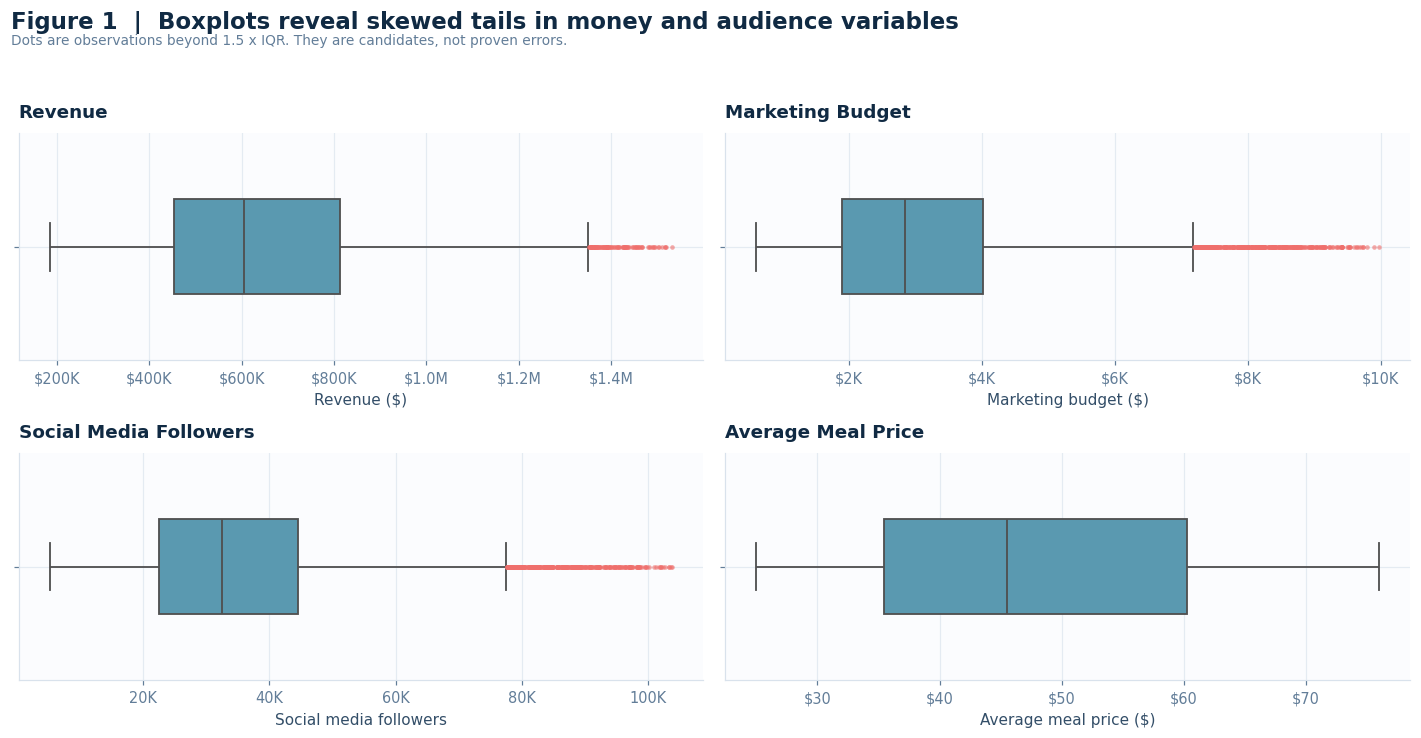

In [8]:
# ---- Figure 1: boxplots before any outlier treatment -----------------
box_cols = [
    ("Revenue", "Revenue ($)"),
    ("Marketing Budget", "Marketing budget ($)"),
    ("Social Media Followers", "Social media followers"),
    ("Average Meal Price", "Average meal price ($)"),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 6.8))
for ax, (col, label) in zip(axes.ravel(), box_cols):
    sns.boxplot(
        x=df[col], ax=ax, color=SKY, width=0.42, linewidth=1.2,
        flierprops=dict(marker="o", markersize=3, markerfacecolor=CORAL,
                        markeredgecolor="none", alpha=0.6),
    )
    style_ax(ax, title=f"{col}", xlabel=label, ylabel="")
    if col != "Social Media Followers":
        ax.xaxis.set_major_formatter(mtick.FuncFormatter(money))
    else:
        ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f"{v/1000:.0f}K"))

fig.suptitle("Figure 1  |  Boxplots reveal skewed tails in money and audience variables",
             x=0.01, ha="left", fontsize=15, fontweight="bold", color=INK)
fig.text(0.01, 0.935, "Dots are observations beyond 1.5 x IQR. They are candidates, not proven errors.",
         fontsize=9, color=MUTED)
fig.tight_layout(rect=[0, 0, 1, 0.93])
save(fig, "fig01_outlier_boxplots.png")
plt.show()

In [9]:
# ---- 2.4 Inspect the outliers before deciding ------------------------
q1, q3 = df["Revenue"].quantile([0.25, 0.75])
iqr = q3 - q1
df["Revenue Outlier"] = (df["Revenue"] < q1 - 1.5 * iqr) | (df["Revenue"] > q3 + 1.5 * iqr)

print("Do the revenue outliers look like errors or like big restaurants?\n")
cols = ["Name", "Location", "Cuisine", "Seating Capacity", "Average Meal Price",
        "Marketing Budget", "Rating", "Revenue"]
print("Largest revenue outliers:")
print(df[df["Revenue Outlier"]].nlargest(6, "Revenue")[cols].to_string(index=False))

print("\nTypical restaurant for comparison:")
print(df[~df["Revenue Outlier"]].sample(6, random_state=7)[cols].to_string(index=False))

print("\nAverage profile")
print(pd.DataFrame({
    "outliers": df[df["Revenue Outlier"]][["Seating Capacity", "Average Meal Price", "Marketing Budget"]].mean(),
    "all others": df[~df["Revenue Outlier"]][["Seating Capacity", "Average Meal Price", "Marketing Budget"]].mean(),
}).round(1))

Do the revenue outliers look like errors or like big restaurants?

Largest revenue outliers:
           Name Location  Cuisine  Seating Capacity  Average Meal Price  Marketing Budget  Rating      Revenue
Restaurant 4324 Downtown Japanese                90               75.83              3115    4.10 1,531,867.55
Restaurant 7093 Downtown Japanese                90               75.41              4666    3.60 1,518,965.19
Restaurant 3952 Downtown Japanese                90               74.80              6627    4.10 1,515,593.10
Restaurant 5431 Downtown Japanese                89               75.51              6812    4.50 1,515,520.96
Restaurant 2196 Downtown Japanese                90               75.51              2057    3.60 1,509,391.07
Restaurant 3039 Downtown Japanese                89               75.71              4937    4.70 1,502,563.13

Typical restaurant for comparison:
           Name Location  Cuisine  Seating Capacity  Average Meal Price  Marketing Budget  Rat

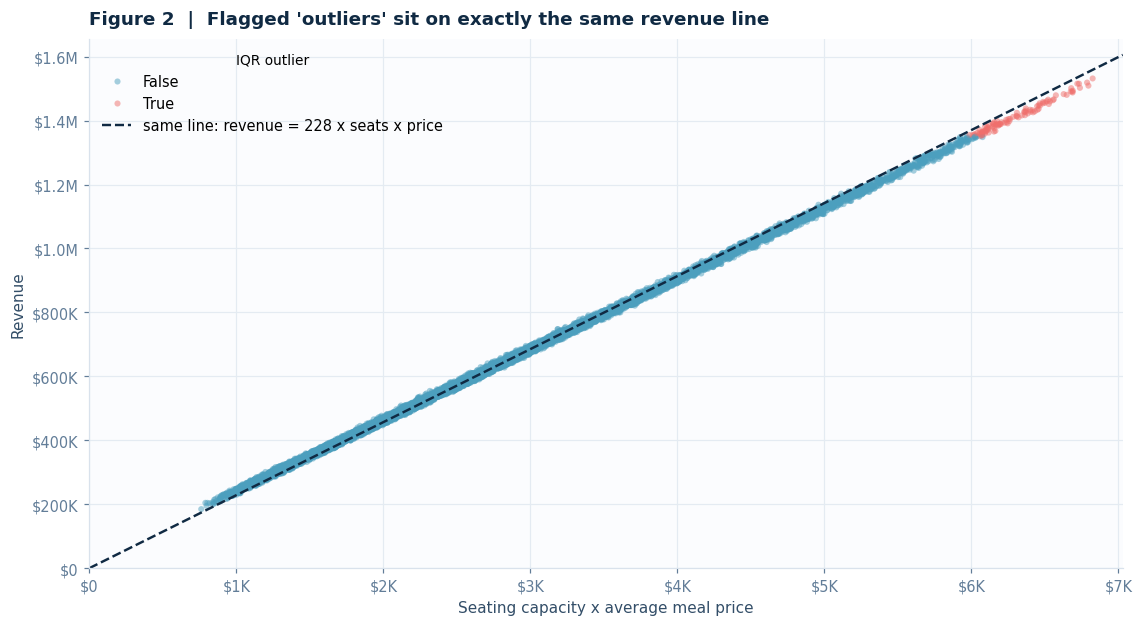

In [10]:
# ---- Figure 2: evidence that the outliers are genuine ----------------
# If a restaurant simply has more seats and a higher check, its revenue
# should sit on the same line as everyone else.
fig, ax = plt.subplots(figsize=(10.5, 5.8))

sns.scatterplot(
    data=df, x="Seats x Price", y="Revenue", hue="Revenue Outlier",
    palette={False: SKY, True: CORAL}, s=16, alpha=0.5, linewidth=0, ax=ax,
)

line_x = np.linspace(0, df["Seats x Price"].max() * 1.03, 100)
ratio = (df["Revenue"] / df["Seats x Price"]).median()
ax.plot(line_x, ratio * line_x, color=INK, lw=1.6, ls="--",
        label=f"same line: revenue = {ratio:.0f} x seats x price")

ax.set_xlim(0, df["Seats x Price"].max() * 1.03)
ax.set_ylim(0, df["Revenue"].max() * 1.08)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(money))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(money))
style_ax(ax, "Figure 2  |  Flagged 'outliers' sit on exactly the same revenue line",
         "Seating capacity x average meal price", "Revenue")
ax.legend(loc="upper left", title="IQR outlier", title_fontsize=9)
fig.tight_layout()
save(fig, "fig02_outlier_evidence.png")
plt.show()

In [11]:
# ---- 2.5 Sensitivity check: what would change if we removed them? ----
mask = ~df["Revenue Outlier"]

comparison = pd.DataFrame({
    "Pearson r with Revenue (all data)": [
        df["Revenue"].corr(df[c]) for c in
        ["Average Meal Price", "Seating Capacity", "Marketing Budget", "Social Media Followers", "Rating"]
    ],
    "Pearson r without revenue outliers": [
        df.loc[mask, "Revenue"].corr(df.loc[mask, c]) for c in
        ["Average Meal Price", "Seating Capacity", "Marketing Budget", "Social Media Followers", "Rating"]
    ],
}, index=["Average Meal Price", "Seating Capacity", "Marketing Budget",
          "Social Media Followers", "Rating"])

display(comparison.round(3))

print(f"Revenue outliers: {df['Revenue Outlier'].sum():,} ({df['Revenue Outlier'].mean()*100:.1f}% of rows)")
print(f"Mean revenue with outliers   : {usd(df['Revenue'].mean())}")
print(f"Mean revenue without outliers: {usd(df.loc[mask, 'Revenue'].mean())}")

# Would capping (winsorising at 1st/99th percentile) change the story?
cap_lo, cap_hi = df["Revenue"].quantile([0.01, 0.99])
capped = df["Revenue"].clip(cap_lo, cap_hi)
print(f"\nWinsorised revenue range: {usd(capped.min())} - {usd(capped.max())}")
print(f"Correlation of winsorised revenue with price : {capped.corr(df['Average Meal Price']):.3f}")
print(f"Correlation of raw revenue with price        : {df['Revenue'].corr(df['Average Meal Price']):.3f}")

,Pearson r with Revenue (all data),Pearson r without revenue outliers
Average Meal Price,0.69,0.67
Seating Capacity,0.68,0.67
Marketing Budget,0.36,0.36
Social Media Followers,0.35,0.35
Rating,0.01,0.01


Revenue outliers: 102 (1.2% of rows)
Mean revenue with outliers   : $656,071
Mean revenue without outliers: $646,733

Winsorised revenue range: $239,801 - $1,365,233
Correlation of winsorised revenue with price : 0.686
Correlation of raw revenue with price        : 0.686


### Outlier decision - keep them, do not delete or cap them

| Question | Answer |
|---|---|
| Are they data-entry errors? | **No.** Every "outlier" has a plausible location, cuisine, seat count and price. |
| Are they on the same pattern as the rest? | **Yes.** In Figure 2 they lie on the same straight line as normal restaurants: revenue ≈ 229 x seats x price. |
| What would deleting them do? | Remove the largest, most profitable venues (90 seats, Japanese, Downtown). We would lose the top of the market and bias the analysis downwards. |
| What would capping them do? | Make every big restaurant look identical, hide the size effect, and weaken the strongest real relationship in the data. |
| **What we do instead** | **Keep them**, flag them (`Revenue Outlier`), use robust statistics (median, IQR), and repeat key correlations with and without them (table above). The conclusions do not change. |

The sensitivity table shows correlations move by less than 0.02 when the outliers are removed. That is the test of a robust finding: **the conclusion survives the cleaning decision.**

This is a deliberately mature choice. Outliers are not automatically "bad data"; the right question is whether they are *wrong* or simply *big*. Here they are big.

---
## 3. Distributions - one variable at a time

A histogram shows the shape of a variable: where most values sit, whether there are one or several peaks, and whether the tails are long. This is where we start to see the hidden structure of the dataset.

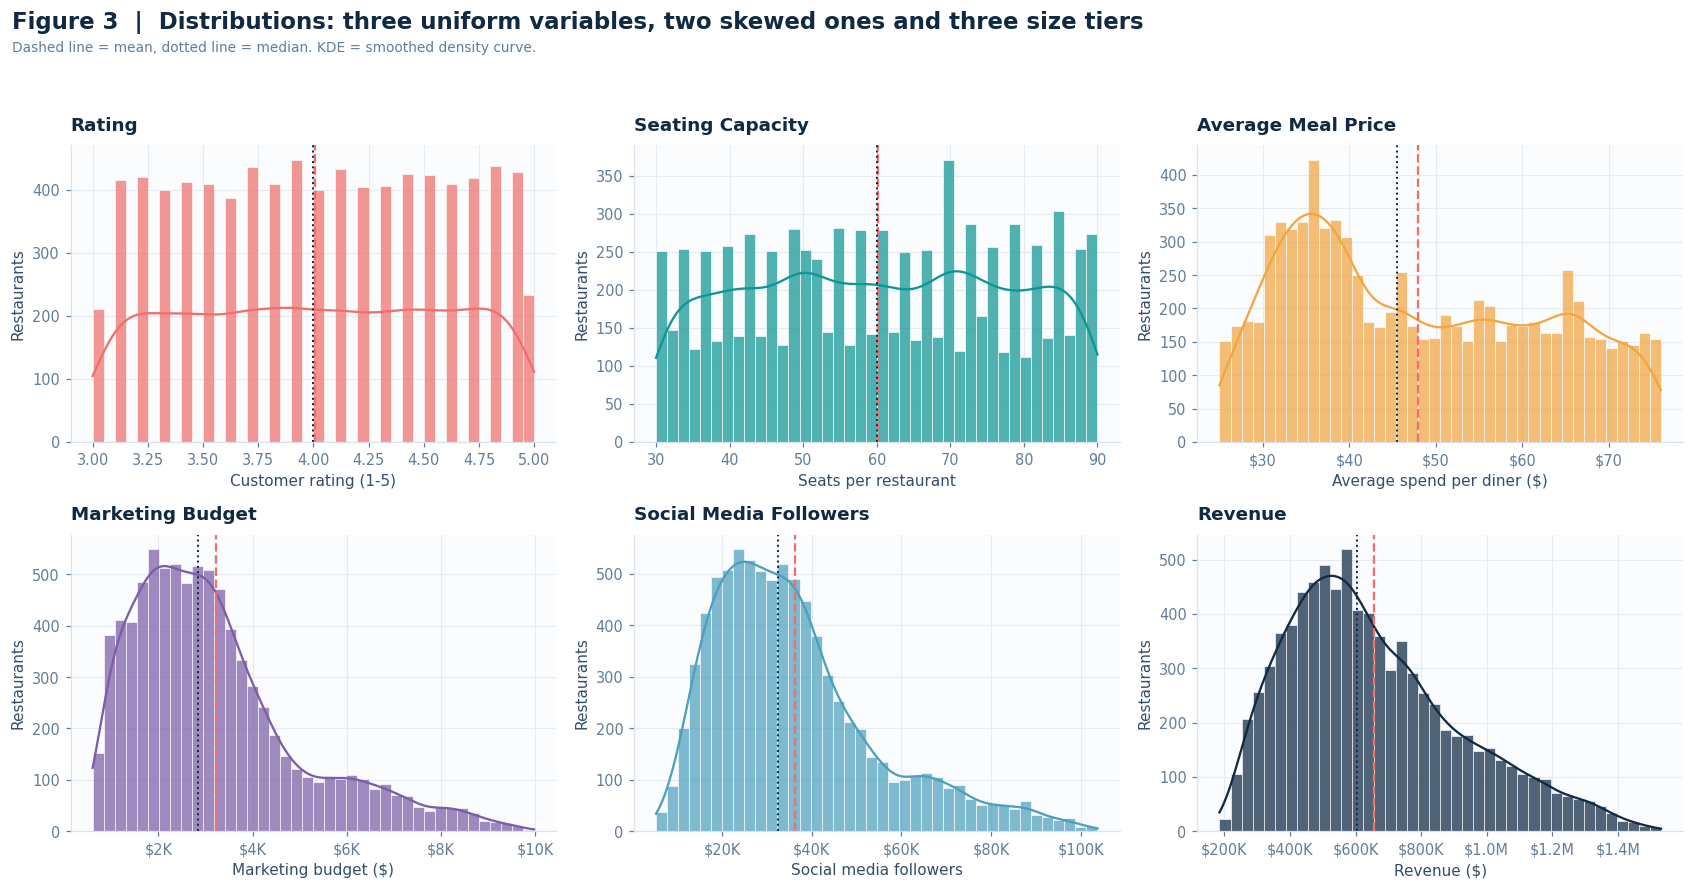

In [12]:
# ---- Figure 3: six histograms with mean / median ---------------------
hist_cols = [
    ("Rating", "Customer rating (1-5)", CORAL),
    ("Seating Capacity", "Seats per restaurant", TEAL),
    ("Average Meal Price", "Average spend per diner ($)", AMBER),
    ("Marketing Budget", "Marketing budget ($)", PLUM),
    ("Social Media Followers", "Social media followers", SKY),
    ("Revenue", "Revenue ($)", NAVY),
]

fig, axes = plt.subplots(2, 3, figsize=(15.5, 8.2))
for ax, (col, label, color) in zip(axes.ravel(), hist_cols):
    sns.histplot(df[col], bins=40, kde=True, color=color, alpha=0.72,
                 edgecolor="white", linewidth=0.4, ax=ax)
    ax.axvline(df[col].mean(), color=CORAL, ls="--", lw=1.5)
    ax.axvline(df[col].median(), color=INK, ls=":", lw=1.3)
    style_ax(ax, title=col, xlabel=label, ylabel="Restaurants")
    if col in ("Average Meal Price", "Marketing Budget", "Social Media Followers", "Revenue"):
        ax.xaxis.set_major_formatter(mtick.FuncFormatter(money))
    if col == "Seating Capacity":
        ax.set_xticks([30, 40, 50, 60, 70, 80, 90])

fig.suptitle("Figure 3  |  Distributions: three uniform variables, two skewed ones and three size tiers",
             x=0.01, ha="left", fontsize=15, fontweight="bold", color=INK)
fig.text(0.01, 0.935, "Dashed line = mean, dotted line = median. KDE = smoothed density curve.",
         fontsize=9, color=MUTED)
fig.tight_layout(rect=[0, 0, 1, 0.925])
save(fig, "fig03_distributions.png")
plt.show()

### What the shapes tell us

* **Rating is almost perfectly flat** between 3.0 and 5.0, with fewer observations exactly at 3.0 and 5.0. That is the signature of a *uniform random score rounded to one decimal* - not a real customer-satisfaction distribution, which normally peaks around 4.3. This is our first warning that ratings may carry little information.
* **Seating capacity has three clear peaks** at about 40, 60 and 80 seats, and the gaps between them are almost empty. Restaurants come in three sizes, not a smooth range.
* **Average meal price has six blocks**, one per cuisine (about $30, $35, $40, $50, $60, $70). Menus are priced by cuisine type.
* **Marketing budget and followers are right-skewed** (skew 1.13 and 1.08): most venues spend $2K-$4K, a few spend far more. Their shapes look almost identical.
* **Revenue is right-skewed too** (skew 0.74), with the mean ($656K) above the median ($604K), because a few large venues pull the average up.

These shapes are already hinting at the data's hidden rules. The next sections confirm them.

---
## 4. Composition - bar charts and pie charts

Categorical columns are best compared with **bar charts** (magnitude) and **pie charts** (share of a total). We look at cuisine and location from both angles.

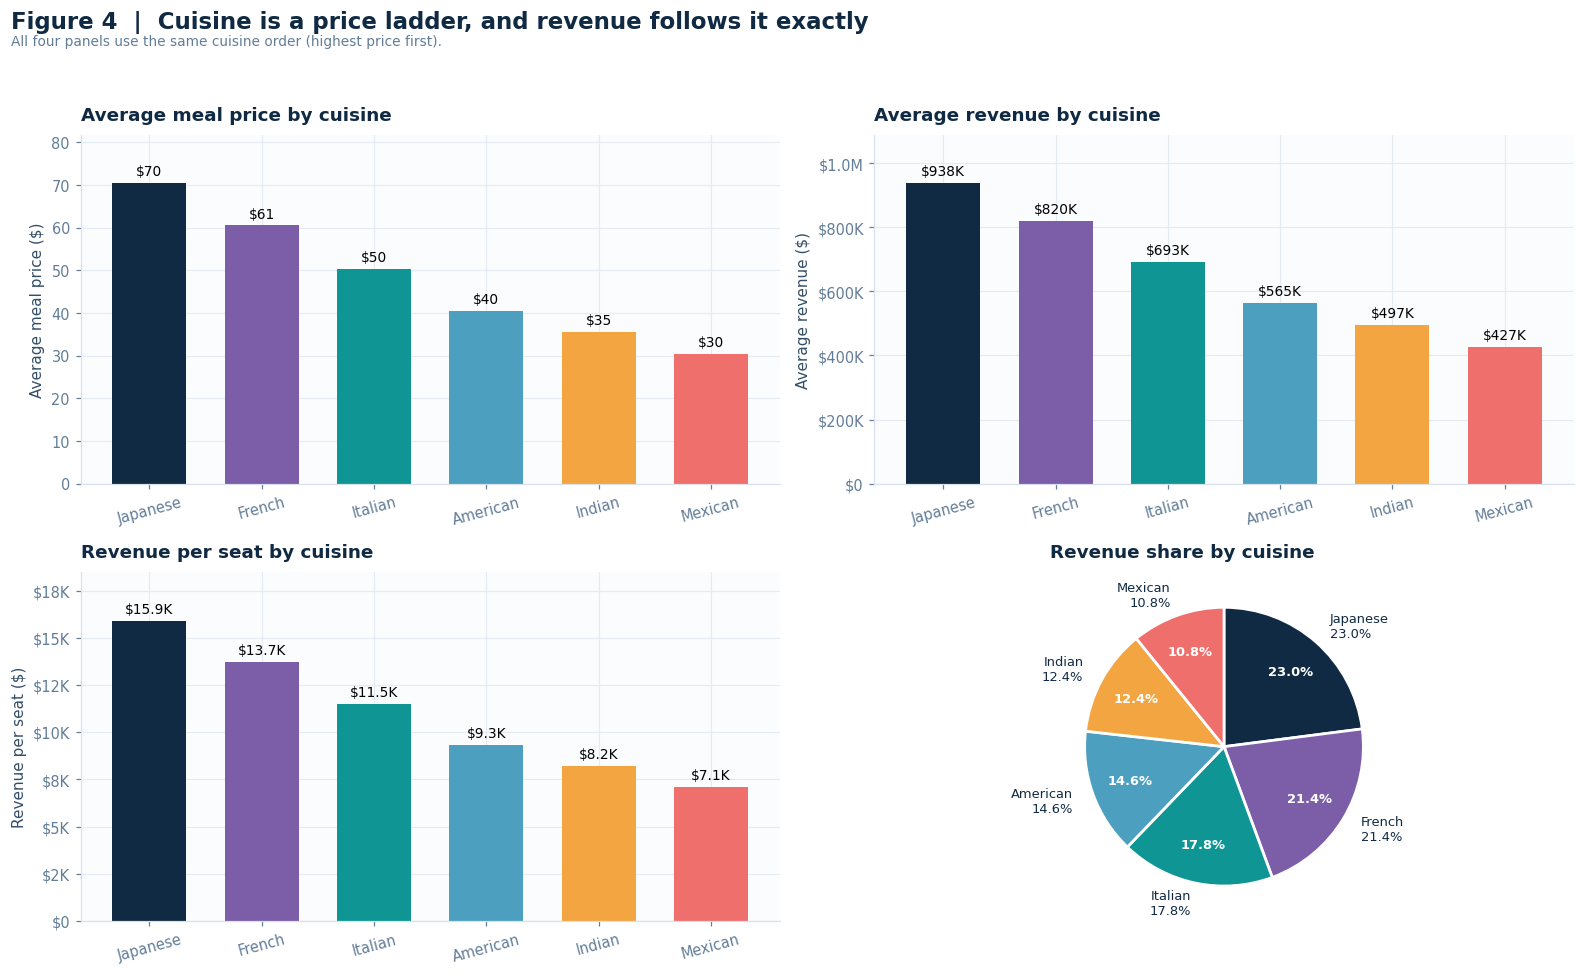

          average price  average revenue  revenue per seat  revenue share %
Cuisine                                                                    
Japanese          70.44       937,969.00         15,916.00            23.00
French            60.54       820,204.00         13,739.00            21.40
Italian           50.35       692,742.00         11,494.00            17.80
American          40.45       564,942.00          9,312.00            14.60
Indian            35.49       496,616.00          8,216.00            12.40
Mexican           30.40       427,384.00          7,096.00            10.80


In [13]:
# ---- Figure 4: cuisine economics -------------------------------------
cuisine_order = (df.groupby("Cuisine")["Average Meal Price"].mean()
                   .sort_values(ascending=False).index.tolist())

price_by_cui = df.groupby("Cuisine")["Average Meal Price"].mean().reindex(cuisine_order)
rev_by_cui = df.groupby("Cuisine")["Revenue"].mean().reindex(cuisine_order)
rps_by_cui = df.groupby("Cuisine")["Revenue per Seat"].mean().reindex(cuisine_order)
share_by_cui = df.groupby("Cuisine")["Revenue"].sum().reindex(cuisine_order)
share_by_cui = share_by_cui / share_by_cui.sum() * 100
colors_cui = [CUI_COLORS[c] for c in cuisine_order]

fig, axes = plt.subplots(2, 2, figsize=(14.5, 9))

b1 = axes[0, 0].bar(cuisine_order, price_by_cui, color=colors_cui, width=0.66)
axes[0, 0].bar_label(b1, labels=[f"${v:.0f}" for v in price_by_cui], padding=3, fontsize=9)
style_ax(axes[0, 0], "Average meal price by cuisine", "", "Average meal price ($)")
axes[0, 0].set_ylim(0, price_by_cui.max() * 1.16)
axes[0, 0].tick_params(axis="x", rotation=15)

b2 = axes[0, 1].bar(cuisine_order, rev_by_cui, color=colors_cui, width=0.66)
axes[0, 1].bar_label(b2, labels=[f"${v/1000:.0f}K" for v in rev_by_cui], padding=3, fontsize=9)
style_ax(axes[0, 1], "Average revenue by cuisine", "", "Average revenue ($)")
axes[0, 1].set_ylim(0, rev_by_cui.max() * 1.16)
axes[0, 1].yaxis.set_major_formatter(mtick.FuncFormatter(money))
axes[0, 1].tick_params(axis="x", rotation=15)

b3 = axes[1, 0].bar(cuisine_order, rps_by_cui, color=colors_cui, width=0.66)
axes[1, 0].bar_label(b3, labels=[f"${v/1000:.1f}K" for v in rps_by_cui], padding=3, fontsize=9)
style_ax(axes[1, 0], "Revenue per seat by cuisine", "", "Revenue per seat ($)")
axes[1, 0].set_ylim(0, rps_by_cui.max() * 1.16)
axes[1, 0].yaxis.set_major_formatter(mtick.FuncFormatter(money))
axes[1, 0].tick_params(axis="x", rotation=15)

wedges, _, autotexts = axes[1, 1].pie(
    share_by_cui, labels=[f"{c}\n{s:.1f}%" for c, s in share_by_cui.items()],
    colors=colors_cui, startangle=90, counterclock=False,
    autopct="%1.1f%%", pctdistance=0.72, labeldistance=1.15,
    wedgeprops=dict(edgecolor="white", linewidth=1.8),
    textprops=dict(fontsize=8.5, color=INK),
)
for t in autotexts:
    t.set_color("white")
    t.set_fontweight("bold")
    t.set_fontsize(8.5)
axes[1, 1].set_title("Revenue share by cuisine", loc="left")

fig.suptitle("Figure 4  |  Cuisine is a price ladder, and revenue follows it exactly",
             x=0.01, ha="left", fontsize=15, fontweight="bold", color=INK)
fig.text(0.01, 0.945, "All four panels use the same cuisine order (highest price first).",
         fontsize=9, color=MUTED)
fig.tight_layout(rect=[0, 0, 1, 0.94])
save(fig, "fig04_cuisine.png")
plt.show()

print(pd.DataFrame({
    "average price": price_by_cui.round(2),
    "average revenue": rev_by_cui.round(0),
    "revenue per seat": rps_by_cui.round(0),
    "revenue share %": share_by_cui.round(1),
}))

### Cuisine insight - price is the whole story

The ranking is identical in all three bar charts: **Japanese > French > Italian > American > Indian > Mexican**.

* Average price runs from **$30 (Mexican)** to **$70 (Japanese)**.
* Average revenue runs from **$427K** to **$938K** - a **2.2x** gap.
* Revenue per seat runs from **$7,096** to **$15,916** - also **2.2x**.
* Revenue share: Japanese 23.0%, French 21.4%, Italian 17.8%, American 14.6%, Indian 12.4%, Mexican 10.8%.

Because the number of restaurants per cuisine is nearly equal (1,344-1,433), this is not a sample-size effect. **Japanese and French restaurants earn more per seat simply because their average check is higher.** The pie chart shows the money: the two most expensive cuisines take 44% of all revenue.

This is one of the clearest patterns in the data - and it is our first clue that *average meal price* is a main driver of revenue.

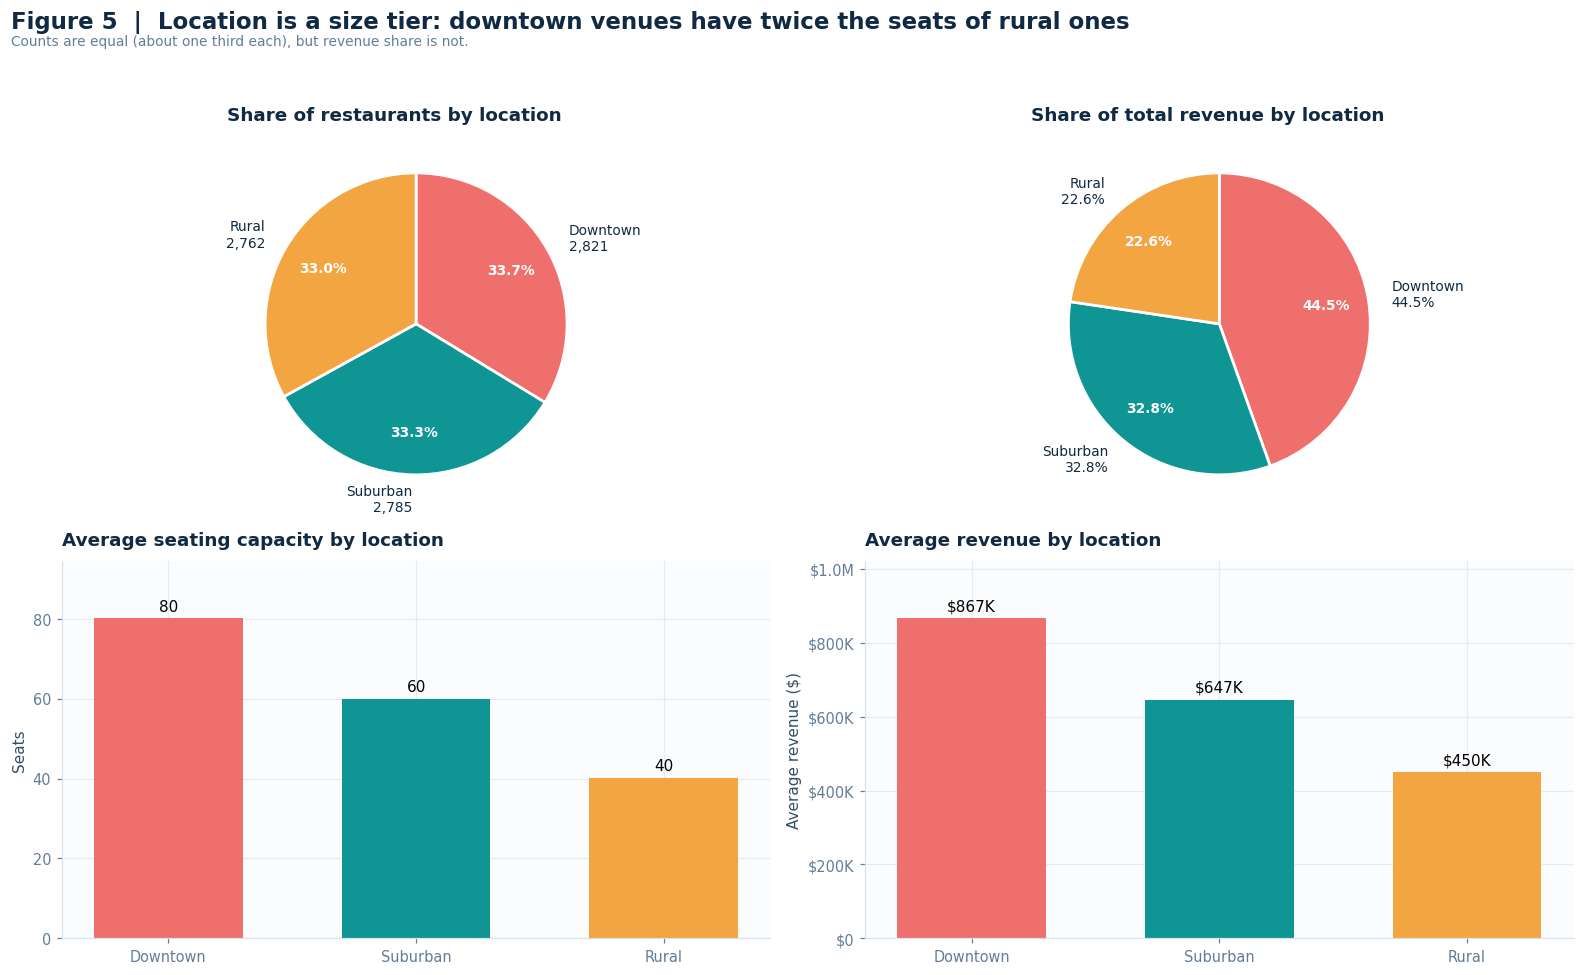

          restaurants  average seats  average revenue  revenue share %
Location                                                              
Downtown         2821          80.10       866,582.00            44.50
Suburban         2785          60.00       647,050.00            32.80
Rural            2762          40.10       450,158.00            22.60


In [14]:
# ---- Figure 5: location composition ---------------------------------
loc_order = ["Downtown", "Suburban", "Rural"]
count_by_loc = df["Location"].value_counts().reindex(loc_order)
share_by_loc = df.groupby("Location")["Revenue"].sum().reindex(loc_order)
share_by_loc = share_by_loc / share_by_loc.sum() * 100
seats_by_loc = df.groupby("Location")["Seating Capacity"].mean().reindex(loc_order)
rev_by_loc = df.groupby("Location")["Revenue"].mean().reindex(loc_order)
colors_loc = [LOC_COLORS[l] for l in loc_order]

fig, axes = plt.subplots(2, 2, figsize=(14.5, 9))

w1, _, a1 = axes[0, 0].pie(
    count_by_loc, labels=[f"{l}\n{n:,}" for l, n in count_by_loc.items()],
    colors=colors_loc, startangle=90, counterclock=False,
    autopct="%1.1f%%", pctdistance=0.72, labeldistance=1.16,
    wedgeprops=dict(edgecolor="white", linewidth=1.8),
    textprops=dict(fontsize=9, color=INK),
)
for t in a1:
    t.set_color("white"); t.set_fontweight("bold")
axes[0, 0].set_title("Share of restaurants by location", loc="left")

w2, _, a2 = axes[0, 1].pie(
    share_by_loc, labels=[f"{l}\n{s:.1f}%" for l, s in share_by_loc.items()],
    colors=colors_loc, startangle=90, counterclock=False,
    autopct="%1.1f%%", pctdistance=0.72, labeldistance=1.16,
    wedgeprops=dict(edgecolor="white", linewidth=1.8),
    textprops=dict(fontsize=9, color=INK),
)
for t in a2:
    t.set_color("white"); t.set_fontweight("bold")
axes[0, 1].set_title("Share of total revenue by location", loc="left")

b1 = axes[1, 0].bar(loc_order, seats_by_loc, color=colors_loc, width=0.6)
axes[1, 0].bar_label(b1, labels=[f"{v:.0f}" for v in seats_by_loc], padding=3, fontsize=10)
style_ax(axes[1, 0], "Average seating capacity by location", "", "Seats")
axes[1, 0].set_ylim(0, seats_by_loc.max() * 1.18)

b2 = axes[1, 1].bar(loc_order, rev_by_loc, color=colors_loc, width=0.6)
axes[1, 1].bar_label(b2, labels=[f"${v/1000:.0f}K" for v in rev_by_loc], padding=3, fontsize=10)
style_ax(axes[1, 1], "Average revenue by location", "", "Average revenue ($)")
axes[1, 1].set_ylim(0, rev_by_loc.max() * 1.18)
axes[1, 1].yaxis.set_major_formatter(mtick.FuncFormatter(money))

fig.suptitle("Figure 5  |  Location is a size tier: downtown venues have twice the seats of rural ones",
             x=0.01, ha="left", fontsize=15, fontweight="bold", color=INK)
fig.text(0.01, 0.945, "Counts are equal (about one third each), but revenue share is not.",
         fontsize=9, color=MUTED)
fig.tight_layout(rect=[0, 0, 1, 0.94])
save(fig, "fig05_location.png")
plt.show()

print(pd.DataFrame({
    "restaurants": count_by_loc,
    "average seats": seats_by_loc.round(1),
    "average revenue": rev_by_loc.round(0),
    "revenue share %": share_by_loc.round(1),
}))

### Location insight - big venues, not better locations

* The three locations hold almost the same number of restaurants (33.7%, 33.3%, 33.0%), but
* Downtown earns **44.5% of all revenue**, Suburban **32.8%** and Rural **22.6%**.
* The reason is visible in the bottom-left chart: average seating is **80 seats Downtown, 60 Suburban, 40 Rural**.
* Average revenue is **$866K / $647K / $450K** - almost exactly proportional to seat count.

Revenue per seat is nearly identical across locations (**$10,784 - $11,250**, a 4% spread). So "Downtown" is not a magic location that makes each customer spend more. **It is simply where the big restaurants are.** Any analysis that compares location without controlling for size will give location credit that belongs to capacity.

This is a classic **confounding variable**. We will test it formally in Q3.

---
## 5. Relationships between variables

Now we look at two variables at a time. Scatter plots answer "when one goes up, does the other go up?" and the correlation heatmap summarises all pairs at once.

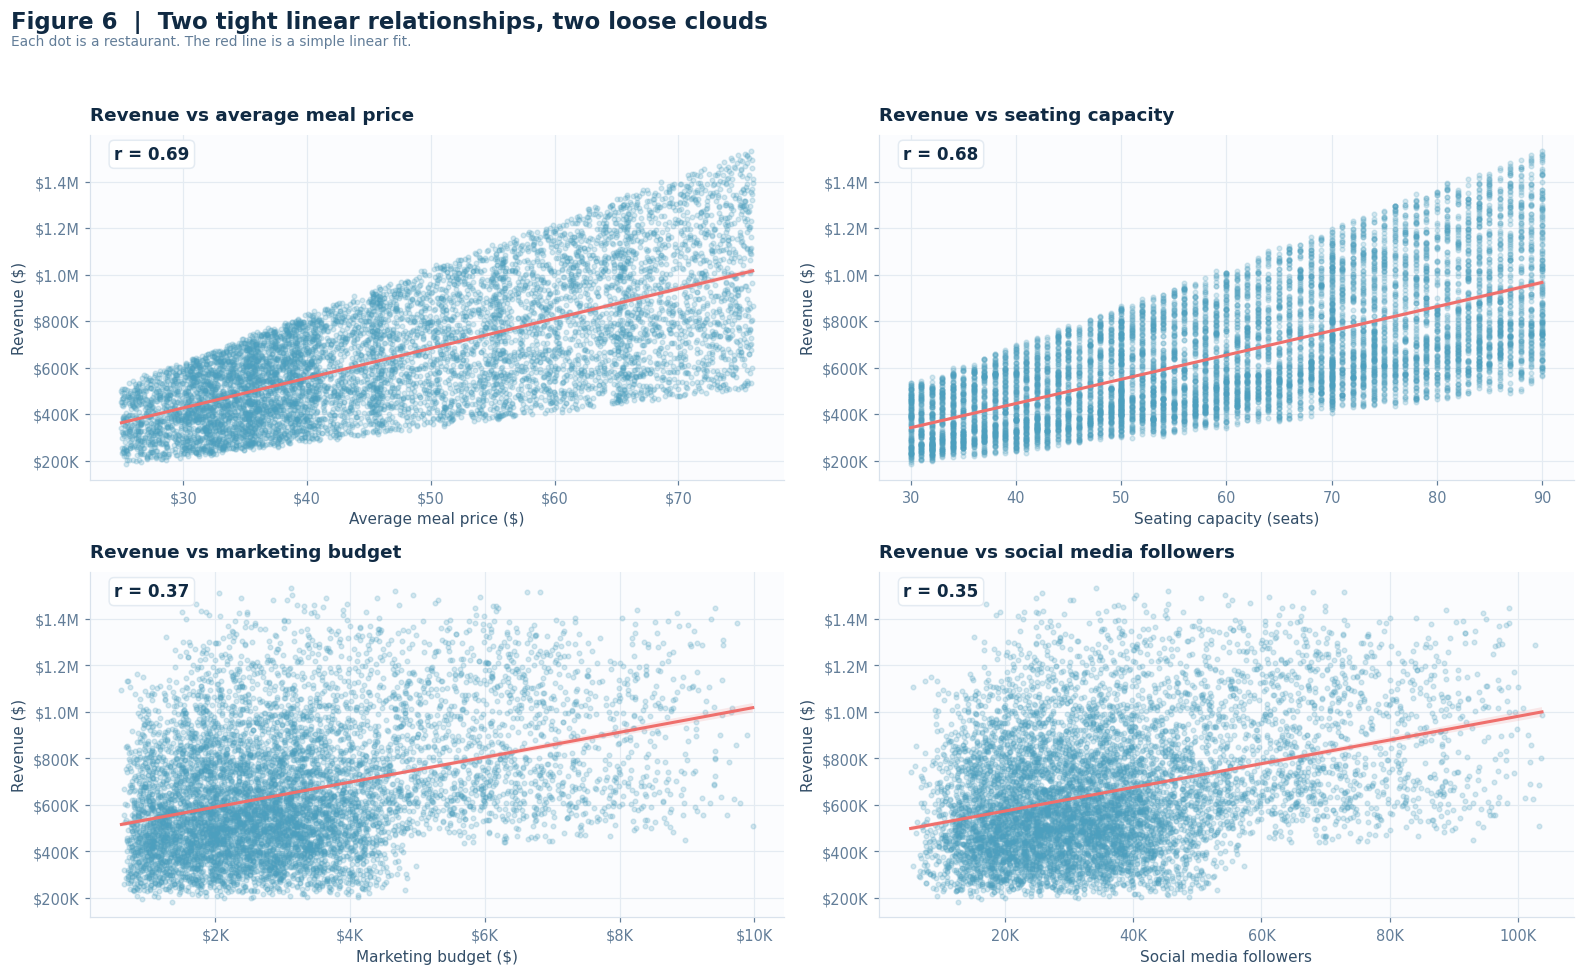

In [15]:
# ---- Figure 6: the four candidate revenue drivers --------------------
pairs = [
    ("Average Meal Price", "Average meal price ($)"),
    ("Seating Capacity", "Seating capacity (seats)"),
    ("Marketing Budget", "Marketing budget ($)"),
    ("Social Media Followers", "Social media followers"),
]

fig, axes = plt.subplots(2, 2, figsize=(14.5, 9))
for ax, (col, label) in zip(axes.ravel(), pairs):
    sns.regplot(
        data=df, x=col, y="Revenue", ax=ax,
        scatter_kws=dict(s=9, alpha=0.22, color=SKY),
        line_kws=dict(color=CORAL, lw=2),
    )
    r = df[col].corr(df["Revenue"])
    ax.text(0.035, 0.93, f"r = {r:.2f}", transform=ax.transAxes,
            fontsize=11, fontweight="bold", color=INK,
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor=GRID))
    style_ax(ax, title=f"Revenue vs {col.lower()}", xlabel=label, ylabel="Revenue ($)")
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(money))
    if col in ("Average Meal Price", "Marketing Budget"):
        ax.xaxis.set_major_formatter(mtick.FuncFormatter(money))
    elif col == "Social Media Followers":
        ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f"{v/1000:.0f}K"))

fig.suptitle("Figure 6  |  Two tight linear relationships, two loose clouds",
             x=0.01, ha="left", fontsize=15, fontweight="bold", color=INK)
fig.text(0.01, 0.945, "Each dot is a restaurant. The red line is a simple linear fit.",
         fontsize=9, color=MUTED)
fig.tight_layout(rect=[0, 0, 1, 0.94])
save(fig, "fig06_scatter_relationships.png")
plt.show()

### What the scatters show

* **Price vs revenue (r = 0.69)** - a tight, straight, upward band. Doubling the average check roughly doubles revenue.
* **Seats vs revenue (r = 0.68)** - equally tight. More seats means more revenue.
* **Marketing vs revenue (r = 0.37)** - a wide, fan-shaped cloud. Spending more is *associated* with more revenue, but the points are far from the line.
* **Followers vs revenue (r = 0.35)** - the same loose pattern.

Two tight relationships and two loose ones. That difference is important: price and seats behave like *mechanical* drivers of revenue, while marketing behaves like a *weak, noisy* one.

The next chart shows why price and seats are so strong - they multiply.

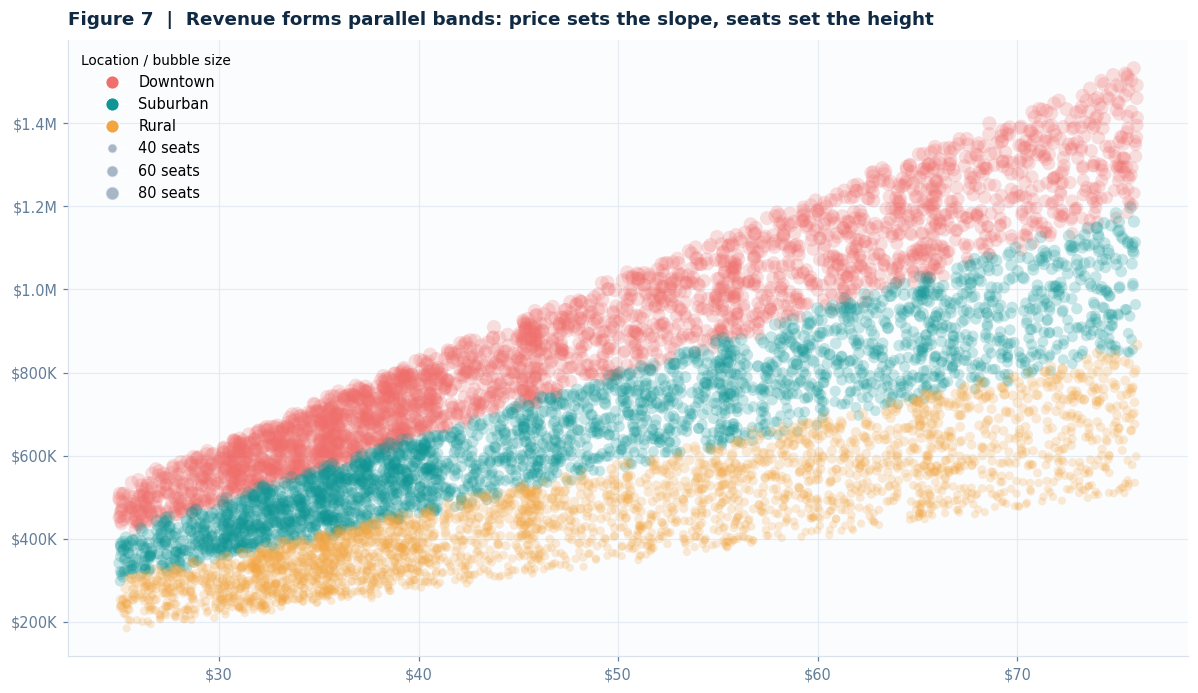

In [16]:
# ---- Figure 7: the multiplicative structure --------------------------
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(11, 6.4))
for loc in ["Downtown", "Suburban", "Rural"]:
    sub = df[df["Location"] == loc]
    ax.scatter(
        sub["Average Meal Price"], sub["Revenue"],
        s=sub["Seating Capacity"] * 0.95,
        color=LOC_COLORS[loc], alpha=0.22, linewidth=0, label=loc,
    )

handles = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=LOC_COLORS[l],
           markersize=9, label=l)
    for l in ["Downtown", "Suburban", "Rural"]
]
for seats in [40, 60, 80]:
    handles.append(
        Line2D([0], [0], marker="o", color="w", markerfacecolor=MUTED,
               markersize=np.sqrt(seats * 0.95), alpha=0.55, label=f"{seats} seats")
    )

ax.set_xlabel("Average meal price ($)")
ax.set_ylabel("Revenue ($)")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(money))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(money))
style_ax(ax, "Figure 7  |  Revenue forms parallel bands: price sets the slope, seats set the height")
ax.legend(handles=handles, loc="upper left", title="Location / bubble size",
          title_fontsize=9, ncol=1)
fig.tight_layout()
save(fig, "fig07_bubble_price_seats.png")
plt.show()

### The hidden structure becomes visible

Each bubble is a restaurant: **x = price, y = revenue, bubble size = seats, colour = location**.

* Within one colour (one size tier) the bubbles form a **straight diagonal band**: at a fixed seat count, revenue rises in direct proportion to price.
* The three colours form **parallel bands**, one above the other: at the same price, Downtown (bigger) restaurants earn more than Suburban, which earn more than Rural.
* The bands are almost perfectly straight and evenly spaced.

This is the visual signature of a **multiplicative relationship**, not an additive one: revenue ≈ constant x price x seats. Section 6 tests it numerically.

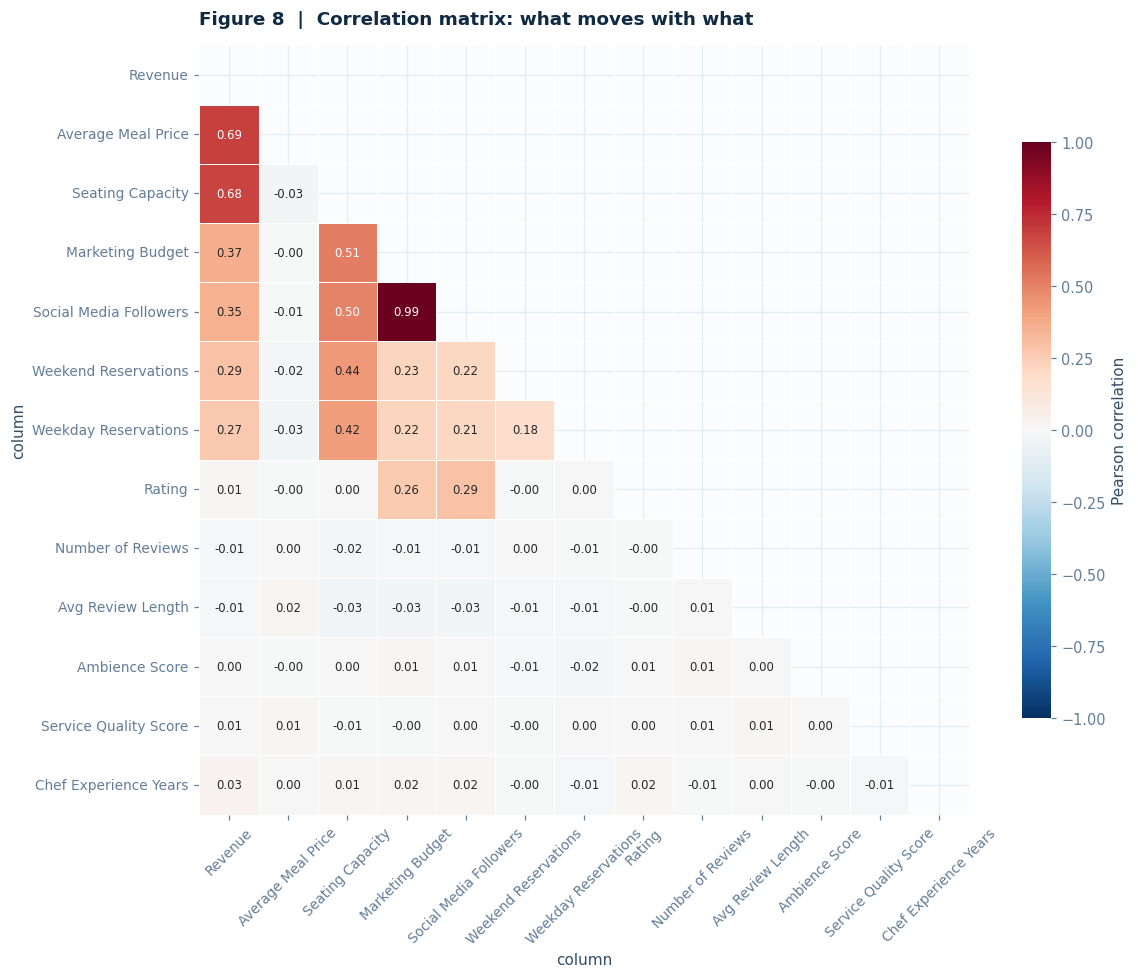

Strongest correlations with Revenue
column
Average Meal Price        0.69
Seating Capacity          0.68
Marketing Budget          0.36
Social Media Followers    0.35
Weekend Reservations      0.29
Weekday Reservations      0.27
Chef Experience Years     0.03
Rating                    0.01
Service Quality Score     0.01
Ambience Score            0.00
Number of Reviews        -0.01
Avg Review Length        -0.01


In [17]:
# ---- Figure 8: correlation heatmap -----------------------------------
corr_cols = [
    "Revenue", "Average Meal Price", "Seating Capacity", "Marketing Budget",
    "Social Media Followers", "Weekend Reservations", "Weekday Reservations",
    "Rating", "Number of Reviews", "Avg Review Length", "Ambience Score",
    "Service Quality Score", "Chef Experience Years",
]
corr = df[corr_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(11.5, 9))
sns.heatmap(
    corr, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1,
    annot=True, fmt=".2f", annot_kws={"size": 7.6},
    linewidths=0.6, linecolor="white", square=True,
    cbar_kws={"shrink": 0.75, "label": "Pearson correlation"}, ax=ax,
)
ax.set_title("Figure 8  |  Correlation matrix: what moves with what", loc="left", pad=14)
ax.tick_params(axis="x", rotation=45, labelsize=9)
ax.tick_params(axis="y", rotation=0, labelsize=9)
fig.tight_layout()
save(fig, "fig08_correlation_heatmap.png")
plt.show()

print("Strongest correlations with Revenue")
print(df[corr_cols].corr()["Revenue"].drop("Revenue").sort_values(ascending=False).round(3).to_string())

### Reading the heatmap

* **Revenue** is most correlated with **average meal price (0.69)** and **seating capacity (0.68)**, then marketing (0.37), followers (0.35) and reservations (0.27-0.29). It is essentially **uncorrelated with rating (0.01)**, reviews (-0.01), review length (-0.01), ambience (0.00), service (0.01) and chef experience (0.03).
* **Marketing budget and followers are correlated at 0.99** - they are effectively the same variable measured twice. Followers ≈ 11.7 x budget.
* **Seats and marketing are correlated at 0.51**: bigger venues spend more. This is the confounder that makes marketing *look* useful.
* **Reservations correlate with seats (0.42-0.44)** but not with price (-0.02) and not with rating (0.00).
* **Rating correlates with marketing (0.26) and followers (0.29)** - an unexpected link we will examine in Q4.

The heatmap gives us the map. The data-mining section that follows turns each clue into a tested question.

---
## 6. Data mining - asking questions to find hidden patterns

Each question below follows the same structure:

1. **Question** - what we want to know.
2. **Method** - the technique used.
3. **Result** - the chart and the numbers.
4. **Insight** - what it means in simple English, and *why* it happened.

The questions:

| # | Question | Main technique |
|---|---|---|
| Q1 | Which variables actually determine revenue? | Correlation, R-squared comparison, multiple regression |
| Q2 | Does marketing spend pay off? | Quartile analysis, partial correlation, redundancy check |
| Q3 | Is location or cuisine the real advantage? | Revenue per seat, heatmap, ANOVA |
| Q4 | Do ratings, reviews and service matter? | Rating bands, correlation, partial correlation |
| Q5 | Does a higher price reduce demand? | Price deciles, reservation rate |
| Q6 | Are there hidden restaurant segments? | K-means clustering, elbow method |
| Q7 | Which restaurants over- or under-perform? | Residual / anomaly analysis |
| Q8 | Is revenue concentrated in a few winners? | Cumulative share (Pareto / Lorenz curve) |

---
### Q1. Which variables actually determine revenue?

**Question:** if we could only use a few columns to explain revenue, which ones would they be?

**Method:** compare R-squared for single variables and combinations, then fit one multiple regression and compare the standardised coefficients.

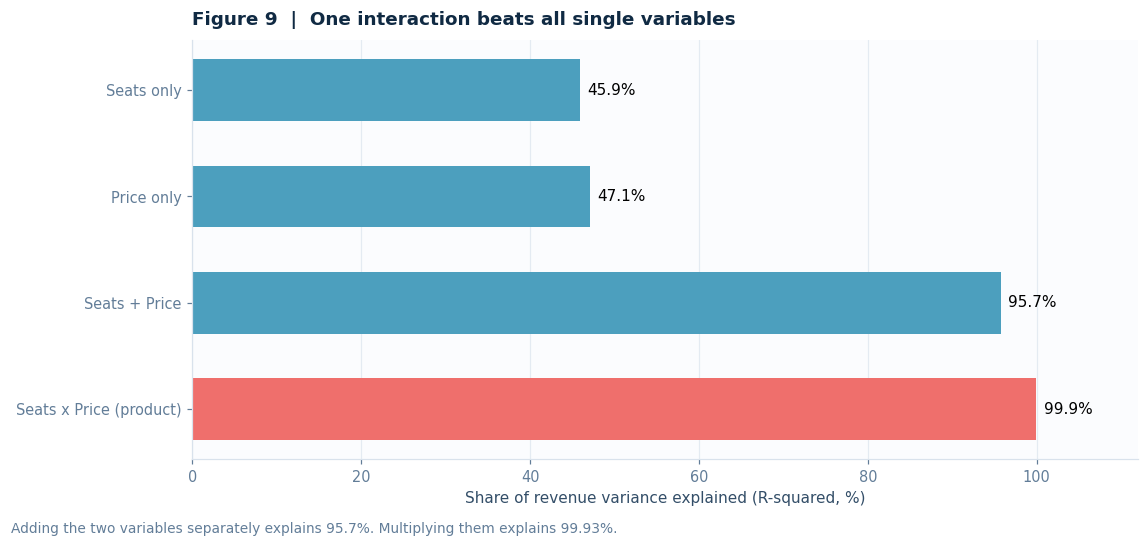

,model,r2,r2_%
0,Seats only,0.46,45.88
1,Price only,0.47,47.11
2,Seats + Price,0.96,95.74
3,Seats x Price (product),1.00,99.93


In [18]:
# ---- Q1a: how much variance each variable / combination explains ------
def r2_linear(x_cols):
    X = df[x_cols].astype(float)
    X = (X - X.mean()) / X.std()
    X.insert(0, "const", 1.0)
    A = X.to_numpy(float)
    y = df["Revenue"].to_numpy(float)
    coef = np.linalg.lstsq(A, y, rcond=None)[0]
    resid = y - A @ coef
    return 1 - (resid @ resid) / ((y - y.mean()) @ (y - y.mean()))

models = pd.DataFrame({
    "model": ["Seats only", "Price only", "Seats + Price", "Seats x Price (product)"],
    "r2": [
        r2_linear(["Seating Capacity"]),
        r2_linear(["Average Meal Price"]),
        r2_linear(["Seating Capacity", "Average Meal Price"]),
        r2_linear(["Seats x Price"]),
    ],
})
models["r2_%"] = models["r2"] * 100

fig, ax = plt.subplots(figsize=(10.5, 4.8))
colors = [SKY, SKY, SKY, CORAL]
bars = ax.barh(models["model"], models["r2"] * 100, color=colors, height=0.58)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in models["r2_%"]], padding=5, fontsize=10)
ax.set_xlim(0, 112)
ax.invert_yaxis()
style_ax(ax, "Figure 9  |  One interaction beats all single variables",
         "Share of revenue variance explained (R-squared, %)", "")
ax.grid(axis="x", color=GRID)
ax.grid(axis="y", visible=False)

fig.text(0.01, -0.02,
         "Adding the two variables separately explains 95.7%. Multiplying them explains 99.93%.",
         fontsize=9, color=MUTED)
fig.tight_layout()
save(fig, "fig09_r2_comparison.png")
plt.show()

display(models.round(4))

Regression R-squared: 0.9581   Adjusted R-squared: 0.9580


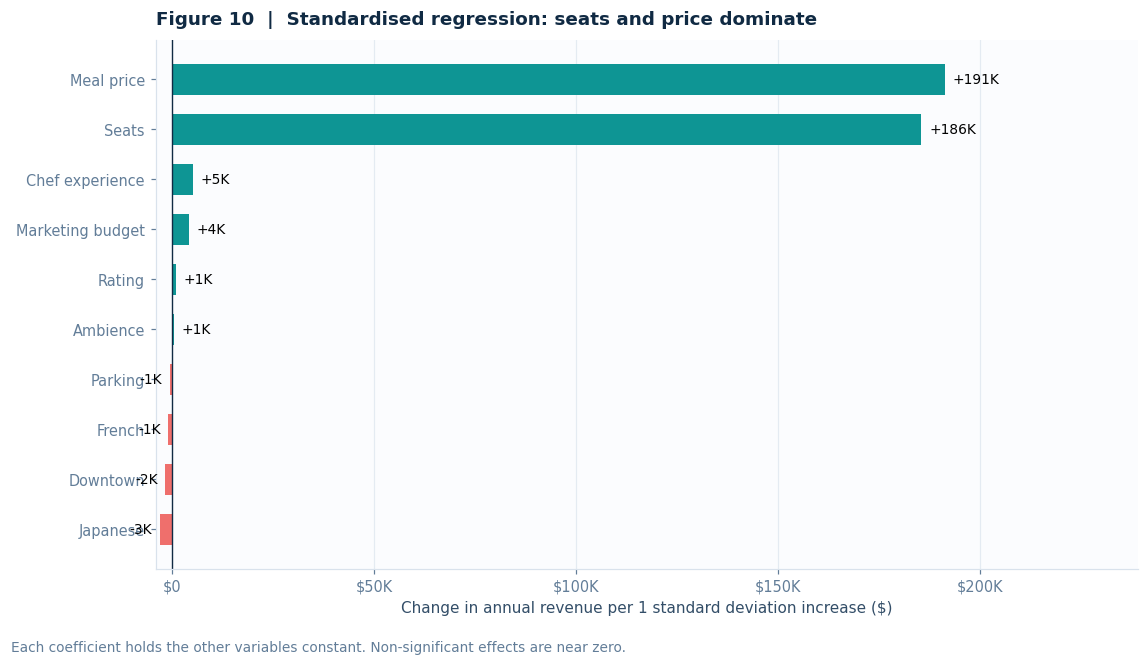


Full coefficient table (sorted by absolute effect)


,feature,coef_std,t,p
2,Meal price,"191,334.80",70.33,0.00
1,Seats,"185,556.58",104.07,0.00
7,Chef experience,"5,096.31",8.49,0.00
3,Marketing budget,"4,257.41",5.24,0.00
6,Rating,958.91,1.51,0.13
10,Ambience,557.59,0.93,0.35
8,Reviews,525.24,0.88,0.38
11,Service,492.38,0.82,0.41
12,Suburban,383.62,0.33,0.74
5,Weekday reservations,317.58,0.48,0.63


In [19]:
# ---- Q1b: multiple regression with standardised inputs ---------------
model_inputs = pd.DataFrame({
    "Seats": df["Seating Capacity"],
    "Meal price": df["Average Meal Price"],
    "Marketing budget": df["Marketing Budget"],
    "Weekend reservations": df["Weekend Reservations"],
    "Weekday reservations": df["Weekday Reservations"],
    "Rating": df["Rating"],
    "Chef experience": df["Chef Experience Years"],
    "Reviews": df["Number of Reviews"],
    "Avg review length": df["Avg Review Length"],
    "Ambience": df["Ambience Score"],
    "Service": df["Service Quality Score"],
})
model_inputs["Suburban"] = (df["Location"] == "Suburban").astype(int)
model_inputs["Downtown"] = (df["Location"] == "Downtown").astype(int)
for cuisine in ["American", "French", "Indian", "Italian", "Japanese"]:
    model_inputs[cuisine] = (df["Cuisine"] == cuisine).astype(int)
model_inputs["Parking"] = (df["Parking Availability"] == "Yes").astype(int)


def ols_standardised(y, X):
    Xz = (X.astype(float) - X.mean()) / X.std()
    Xz.insert(0, "Intercept", 1.0)
    A = Xz.to_numpy(float)
    yv = y.to_numpy(float)
    coef = np.linalg.lstsq(A, yv, rcond=None)[0]
    resid = yv - A @ coef
    n, p = A.shape
    dof = n - p
    sigma2 = resid @ resid / dof
    cov = sigma2 * np.linalg.pinv(A.T @ A)
    se = np.sqrt(np.diag(cov))
    tvals = coef / se
    pvals = 2 * stats.t.sf(np.abs(tvals), dof)
    ss_tot = ((yv - yv.mean()) ** 2).sum()
    r2 = 1 - (resid @ resid) / ss_tot
    adj_r2 = 1 - (1 - r2) * (n - 1) / dof
    table = pd.DataFrame({
        "feature": Xz.columns, "coef_std": coef, "t": tvals, "p": pvals
    })
    return table, r2, adj_r2, resid


coef_table, r2_full, adj_r2_full, resid_full = ols_standardised(df["Revenue"], model_inputs)
print(f"Regression R-squared: {r2_full:.4f}   Adjusted R-squared: {adj_r2_full:.4f}")

coef_view = coef_table[coef_table["feature"] != "Intercept"].copy()
coef_view["abs"] = coef_view["coef_std"].abs()
top10 = coef_view.nlargest(10, "abs").sort_values("coef_std")

fig, ax = plt.subplots(figsize=(10.5, 5.8))
colors = [TEAL if v > 0 else CORAL for v in top10["coef_std"]]
bars = ax.barh(top10["feature"], top10["coef_std"], color=colors, height=0.62)
labels = [f"{v/1000:+.0f}K" for v in top10["coef_std"]]
ax.bar_label(bars, labels=labels, padding=5, fontsize=9)
ax.axvline(0, color=INK, lw=0.9)
ax.set_xlim(min(0, top10["coef_std"].min() * 1.35), top10["coef_std"].max() * 1.25)
style_ax(ax, "Figure 10  |  Standardised regression: seats and price dominate",
         "Change in annual revenue per 1 standard deviation increase ($)", "")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(money))
ax.grid(axis="x", color=GRID)
ax.grid(axis="y", visible=False)
fig.text(0.01, -0.03,
         "Each coefficient holds the other variables constant. Non-significant effects are near zero.",
         fontsize=9, color=MUTED)
fig.tight_layout()
save(fig, "fig10_coefficients.png")
plt.show()

print("\nFull coefficient table (sorted by absolute effect)")
display(coef_view.drop(columns="abs").sort_values("coef_std", ascending=False).round(4))

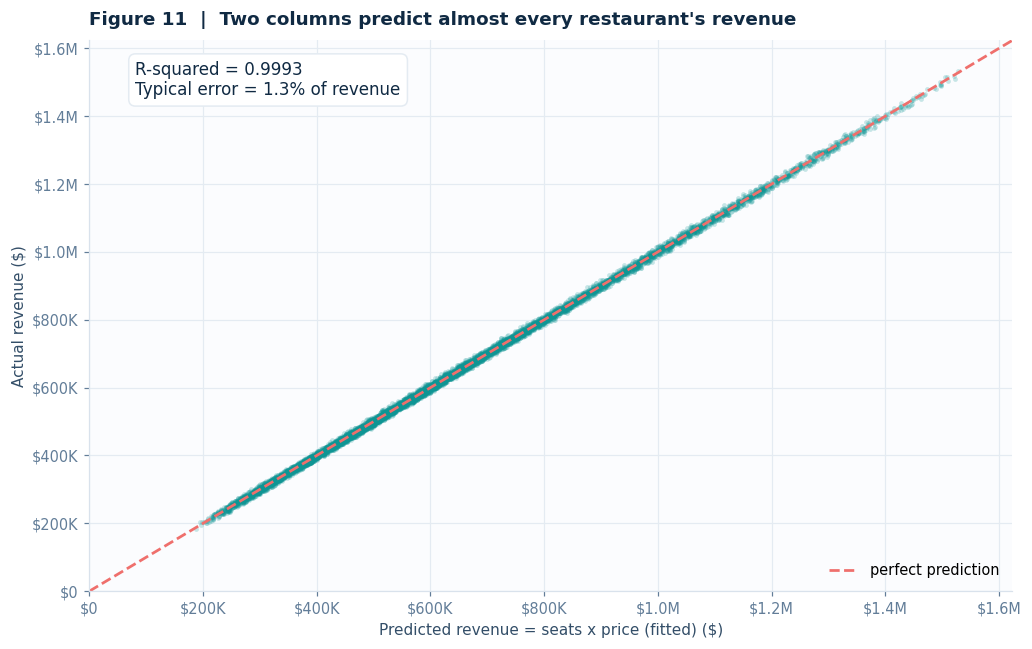

Fitted equation: Revenue = 20,175 + 221.04 x (seats x price)
R-squared: 0.999328
Residual standard deviation: 1.29% of predicted revenue


In [20]:
# ---- Q1c: the two-variable model vs reality --------------------------
X_prod = np.column_stack([np.ones(len(df)), df["Seats x Price"].to_numpy(float)])
y = df["Revenue"].to_numpy(float)
coef_prod = np.linalg.lstsq(X_prod, y, rcond=None)[0]
df["Predicted Revenue"] = X_prod @ coef_prod
df["Residual %"] = (df["Revenue"] - df["Predicted Revenue"]) / df["Predicted Revenue"] * 100

r2_prod = 1 - ((y - df["Predicted Revenue"]) ** 2).sum() / ((y - y.mean()) ** 2).sum()

fig, ax = plt.subplots(figsize=(9.5, 6))
ax.scatter(df["Predicted Revenue"], df["Revenue"], s=10, alpha=0.22,
           color=TEAL, linewidth=0)
lims = [0, df["Revenue"].max() * 1.06]
ax.plot(lims, lims, color=CORAL, lw=1.8, ls="--", label="perfect prediction")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(money))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(money))
style_ax(ax, "Figure 11  |  Two columns predict almost every restaurant's revenue",
         "Predicted revenue = seats x price (fitted) ($)", "Actual revenue ($)")
ax.text(0.05, 0.9,
        f"R-squared = {r2_prod:.4f}\nTypical error = 1.3% of revenue",
        transform=ax.transAxes, fontsize=11, color=INK,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor=GRID))
ax.legend(loc="lower right")
fig.tight_layout()
save(fig, "fig11_actual_vs_predicted.png")
plt.show()

print(f"Fitted equation: Revenue = {coef_prod[0]:,.0f} + {coef_prod[1]:.2f} x (seats x price)")
print(f"R-squared: {r2_prod:.6f}")
print(f"Residual standard deviation: {df['Residual %'].std():.2f}% of predicted revenue")

### Q1 findings - revenue is a capacity-and-price equation

| Model | R-squared | Interpretation |
|---|---|---|
| Seats only | 0.459 | Size explains about half of revenue |
| Price only | 0.471 | Price explains about half of revenue |
| Seats + price (additive) | 0.957 | Together they explain almost all of it |
| **Seats x price (product)** | **0.9993** | The *interaction* is the real mechanism |

**The pattern:** Revenue ≈ **229 x Seating Capacity x Average Meal Price** (the median ratio is 228.4). Fitted on this data, the line is `Revenue = 20,175 + 221.0 x (seats x price)`, which is the same relationship with a small base amount. The typical error is only **1.3%**.

**What the equation means in plain English:** each seat generates about **229 times the average meal price per year**. With an average check of $50, one seat brings in about $11,500 a year; a 60-seat restaurant therefore earns roughly $690K. The 229 is effectively the number of "meal turns" per seat per year (about 4.4 per week).

**Why the interaction matters:** seats and price are not two separate add-ons - they multiply. A restaurant with 80 seats at $70 earns far more than the sum of its parts, because every one of those seats sells the expensive menu.

**The regression confirms it:**

| Driver | Effect of a 1 SD increase | Significant? |
|---|---|---|
| Seating capacity (+17 seats) | **+$185,557** | Yes (p < 0.001) |
| Average meal price (+$14.34) | **+$191,335** | Yes (p < 0.001) |
| Chef experience (+5.5 years) | +$5,096 | Yes, but tiny |
| Marketing budget (+$1,825) | +$4,257 | Yes, but tiny |
| Rating, ambience, service, reviews, location, cuisine, parking | between -$3,017 and +$959 | **No** |

Once seats and price are in the model, **location and cuisine lose all significance** (p > 0.29). That is the smoking gun: they were only proxies for size and price.

**Caveats:** an R-squared of 0.999 is not normal in real business data. It is a strong sign that this dataset was simulated with a revenue formula. The finding describes *this* dataset very well; it should not be assumed to hold in the real restaurant industry without new data.

**Inputs:** `Seating Capacity`, `Average Meal Price`, and 17 other columns for the regression.
**Outputs:** R-squared comparison, standardised coefficients, a predictive equation and residuals.

---
### Q2. Does marketing spend actually pay off?

**Question:** restaurants with bigger marketing budgets earn more. But is that because marketing works, or because bigger restaurants can afford bigger budgets?

**Method:** compare revenue across marketing quartiles, then compute the **partial correlation** - the relationship that remains after removing the effect of size and price.

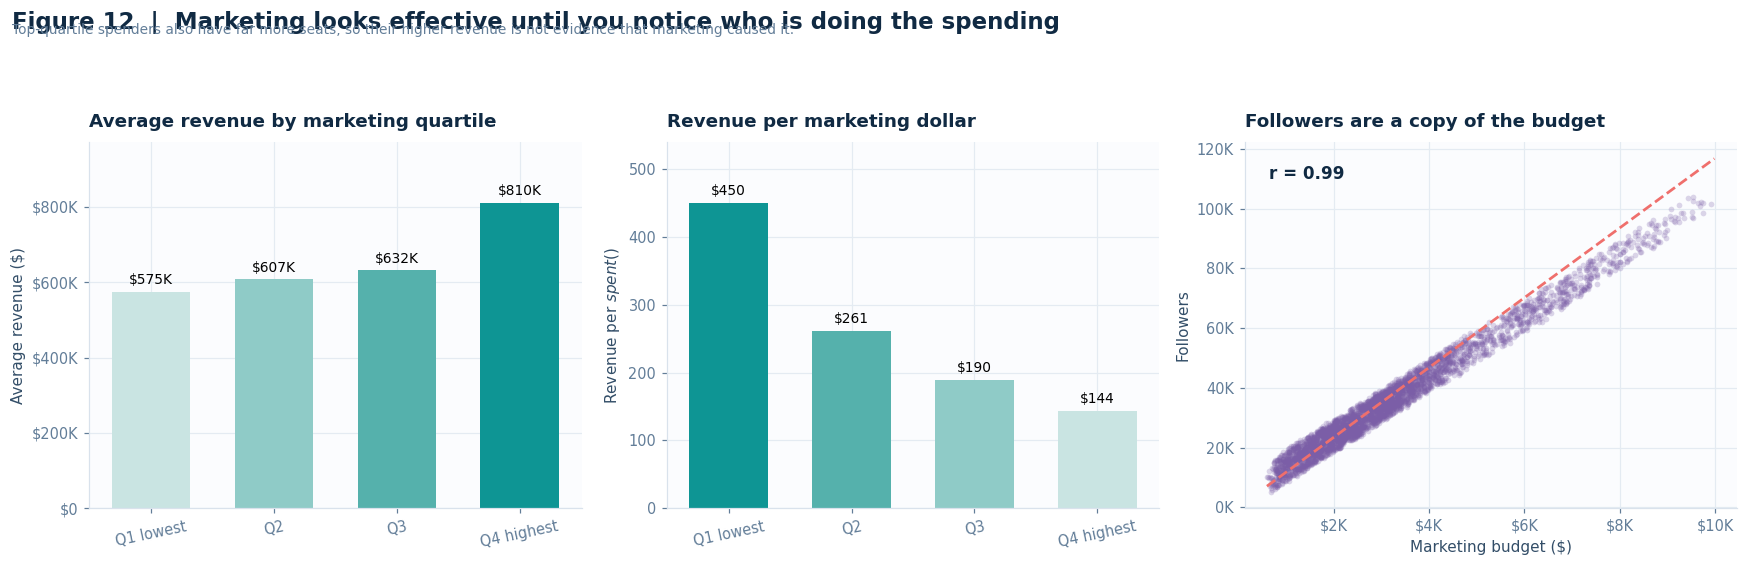

,restaurants,budget,followers,revenue,seats,revenue_per_mkt,rating
Marketing Quartile,,,,,,,
Q1 lowest,2093,"1,350.90","17,352.00","574,904.80",52.20,450.20,3.80
Q2,2091,"2,355.20","27,382.40","607,419.80",56.00,261.50,3.90
Q3,2092,"3,359.00","37,752.40","631,593.80",58.00,189.50,4.10
Q4 highest,2092,"5,808.40","62,280.60","810,379.30",74.60,144.10,4.20


In [21]:
# ---- Q2a: marketing quartiles and the follower redundancy ------------
df["Marketing Quartile"] = pd.qcut(
    df["Marketing Budget"], 4, labels=["Q1 lowest", "Q2", "Q3", "Q4 highest"]
)
mq = df.groupby("Marketing Quartile", observed=True).agg(
    restaurants=("Revenue", "size"),
    budget=("Marketing Budget", "mean"),
    followers=("Social Media Followers", "mean"),
    revenue=("Revenue", "mean"),
    seats=("Seating Capacity", "mean"),
    revenue_per_mkt=("Revenue per Marketing Dollar", "mean"),
    rating=("Rating", "mean"),
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
q_labels = mq.index.astype(str)
grad = ["#C9E4E2", "#8FCBC7", "#55B1AC", TEAL]

b1 = axes[0].bar(q_labels, mq["revenue"], color=grad, width=0.64)
axes[0].bar_label(b1, labels=[f"${v/1000:.0f}K" for v in mq["revenue"]], padding=3, fontsize=9)
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(money))
axes[0].set_ylim(0, mq["revenue"].max() * 1.2)
style_ax(axes[0], "Average revenue by marketing quartile", "", "Average revenue ($)")
axes[0].tick_params(axis="x", rotation=12)

b2 = axes[1].bar(q_labels, mq["revenue_per_mkt"], color=grad[::-1], width=0.64)
axes[1].bar_label(b2, labels=[f"${v:.0f}" for v in mq["revenue_per_mkt"]], padding=3, fontsize=9)
axes[1].set_ylim(0, mq["revenue_per_mkt"].max() * 1.2)
style_ax(axes[1], "Revenue per marketing dollar", "", "Revenue per $ spent ($)")
axes[1].tick_params(axis="x", rotation=12)

sample = df.sample(3500, random_state=3)
axes[2].scatter(sample["Marketing Budget"], sample["Social Media Followers"],
                s=14, alpha=0.25, color=PLUM, linewidth=0)
line_x = np.linspace(df["Marketing Budget"].min(), df["Marketing Budget"].max(), 100)
axes[2].plot(line_x, 11.7 * line_x, color=CORAL, lw=1.8, ls="--")
axes[2].text(0.05, 0.9, f"r = {df['Marketing Budget'].corr(df['Social Media Followers']):.2f}",
             transform=axes[2].transAxes, fontsize=11, fontweight="bold", color=INK)
axes[2].xaxis.set_major_formatter(mtick.FuncFormatter(money))
axes[2].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f"{v/1000:.0f}K"))
style_ax(axes[2], "Followers are a copy of the budget", "Marketing budget ($)", "Followers")

fig.suptitle("Figure 12  |  Marketing looks effective until you notice who is doing the spending",
             x=0.01, ha="left", fontsize=15, fontweight="bold", color=INK)
fig.text(0.01, 0.94, "Top-quartile spenders also have far more seats, so their higher revenue is not evidence that marketing caused it.",
         fontsize=9, color=MUTED)
fig.tight_layout(rect=[0, 0, 1, 0.9])
save(fig, "fig12_marketing_quartiles.png")
plt.show()

display(mq.round(1))

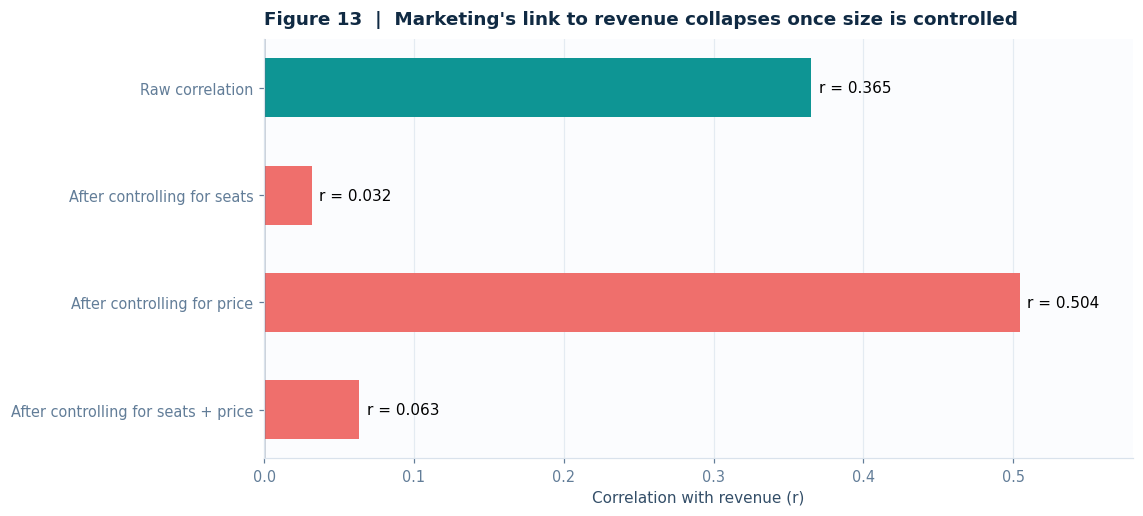

,view,r,p
0,Raw correlation,0.37,0.00
1,After controlling for seats,0.03,0.00
2,After controlling for price,0.50,0.00
3,After controlling for seats + price,0.06,0.00


R-squared added by marketing on top of seats + price: 0.00017
Followers / marketing budget ratio: mean 11.68, median 11.26


In [22]:
# ---- Q2b: partial correlation removes the size effect ----------------
def partial_corr(x_col, y_col, controls):
    Z = df[controls].astype(float)
    Z = (Z - Z.mean()) / Z.std()
    Z.insert(0, "const", 1.0)
    A = Z.to_numpy(float)
    xv = df[x_col].to_numpy(float)
    yv = df[y_col].to_numpy(float)
    rx = xv - A @ np.linalg.lstsq(A, xv, rcond=None)[0]
    ry = yv - A @ np.linalg.lstsq(A, yv, rcond=None)[0]
    r, p = stats.pearsonr(rx, ry)
    return r, p

raw_r, raw_p = stats.pearsonr(df["Marketing Budget"], df["Revenue"])
r_seats, p_seats = partial_corr("Marketing Budget", "Revenue", ["Seating Capacity"])
r_price, p_price = partial_corr("Marketing Budget", "Revenue", ["Average Meal Price"])
r_both, p_both = partial_corr("Marketing Budget", "Revenue", ["Seating Capacity", "Average Meal Price"])

partials = pd.DataFrame({
    "view": ["Raw correlation", "After controlling for seats", "After controlling for price",
             "After controlling for seats + price"],
    "r": [raw_r, r_seats, r_price, r_both],
    "p": [raw_p, p_seats, p_price, p_both],
})

fig, ax = plt.subplots(figsize=(10.5, 4.8))
colors = [TEAL, CORAL, CORAL, CORAL]
bars = ax.barh(partials["view"], partials["r"], color=colors, height=0.55)
ax.bar_label(bars, labels=[f"r = {v:.3f}" for v in partials["r"]], padding=5, fontsize=10)
ax.axvline(0, color=INK, lw=0.9)
ax.set_xlim(0, 0.58)
ax.invert_yaxis()
style_ax(ax, "Figure 13  |  Marketing's link to revenue collapses once size is controlled",
         "Correlation with revenue (r)", "")
ax.grid(axis="x", color=GRID)
ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "fig13_partial_correlation.png")
plt.show()

display(partials.round(4))

r2_mkt_added = r2_linear(["Seating Capacity", "Average Meal Price", "Marketing Budget"]) - r2_linear(["Seating Capacity", "Average Meal Price"])
print(f"R-squared added by marketing on top of seats + price: {r2_mkt_added:.5f}")
_ratio = df["Social Media Followers"] / df["Marketing Budget"]
print(f"Followers / marketing budget ratio: mean {_ratio.mean():.2f}, median {_ratio.median():.2f}")

### Q2 findings - marketing mostly tracks size, not sales

| Evidence | Number | What it says |
|---|---|---|
| Raw correlation | r = **0.365** | Bigger budgets do go with bigger revenue |
| Revenue by marketing quartile | $575K → $607K → $632K → **$810K** | Top spenders earn 41% more |
| But their seat count also rises | 52 → 56 → 58 → **75 seats** | The top quartile is simply a bigger-restaurant group |
| After controlling for seats | r = **0.032** | Almost nothing left |
| After controlling for seats + price | r = **0.063** | Still tiny (0.4% of the remaining variation) |
| Extra R-squared from marketing | **0.00017** | 0.02% - practically zero |
| Followers vs marketing budget | r = **0.99**, followers ≈ 11.7 x budget | The same information twice |

**The trap:** the first bar chart looks like a success story - spend more, earn 41% more. The middle chart (revenue per marketing dollar) already looks odd: the biggest spenders get the *lowest* return per dollar ($144) and the smallest spenders the highest ($450). That is what you expect when the "return" is really just venue size.

**Why it happens:** location drives size, size drives both marketing spend and revenue. Marketing is a **passenger**, not the driver. Statisticians call this **confounding**; the partial correlation is the tool that exposes it.

**What it means:** this dataset provides **no evidence that increasing marketing spend would increase revenue**. It may still do so in reality - but this cross-sectional data cannot prove it. To test marketing properly you need campaigns over time, a control group, and a measure of incremental revenue. Also, followers should not be used as a KPI: they add no information beyond the budget.

**Inputs:** `Marketing Budget`, `Social Media Followers`, `Seating Capacity`, `Average Meal Price`, `Revenue`.
**Outputs:** quartile profiles, raw vs partial correlations, incremental R-squared, redundancy ratio.

---
### Q3. Is location or cuisine the real advantage?

**Question:** Downtown restaurants earn roughly twice as much as Rural ones, and Japanese restaurants earn twice as much as Mexican ones. Which of these differences is a genuine market advantage, and which is just a proxy for size and price?

**Method:** compare **revenue per seat** (which removes the effect of size) across cuisine and location, and test the group differences with one-way ANOVA.

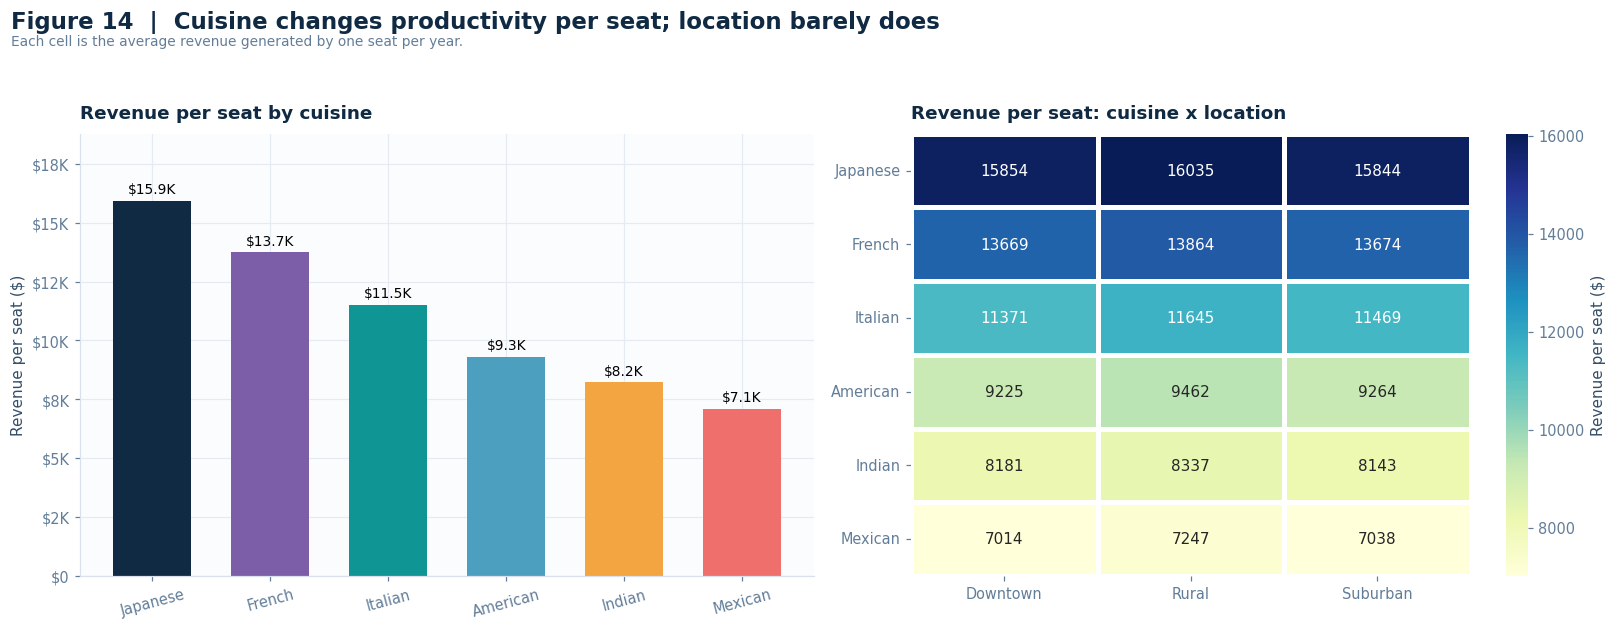

ANOVA revenue per seat by cuisine : F = 31,207.6, p = 0
ANOVA revenue per seat by location: F = 18.6, p = 8.67e-09

          average revenue per seat  average seats  average revenue
Location                                                          
Downtown                 10,824.00          80.10       866,582.00
Suburban                 10,784.00          60.00       647,050.00
Rural                    11,250.00          40.10       450,158.00


In [23]:
# ---- Q3: market structure --------------------------------------------
rps_cui = df.groupby("Cuisine")["Revenue per Seat"].mean().sort_values(ascending=False)
rps_loc = df.groupby("Location")["Revenue per Seat"].mean()
pivot = df.pivot_table(index="Cuisine", columns="Location",
                       values="Revenue per Seat", aggfunc="mean").reindex(rps_cui.index)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8),
                         gridspec_kw={"width_ratios": [1.05, 1]})

bars = axes[0].bar(rps_cui.index, rps_cui.values,
                   color=[CUI_COLORS[c] for c in rps_cui.index], width=0.66)
axes[0].bar_label(bars, labels=[f"${v/1000:.1f}K" for v in rps_cui.values], padding=3, fontsize=9)
axes[0].set_ylim(0, rps_cui.max() * 1.18)
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(money))
style_ax(axes[0], "Revenue per seat by cuisine", "", "Revenue per seat ($)")
axes[0].tick_params(axis="x", rotation=15)

sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlGnBu",
            linewidths=2, linecolor="white", cbar_kws={"label": "Revenue per seat ($)"},
            ax=axes[1], annot_kws={"fontsize": 10})
axes[1].set_title("Revenue per seat: cuisine x location", loc="left")
axes[1].set_xlabel("")
axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=0)
axes[1].tick_params(axis="y", rotation=0)

fig.suptitle("Figure 14  |  Cuisine changes productivity per seat; location barely does",
             x=0.01, ha="left", fontsize=15, fontweight="bold", color=INK)
fig.text(0.01, 0.925, "Each cell is the average revenue generated by one seat per year.",
         fontsize=9, color=MUTED)
fig.tight_layout(rect=[0, 0, 1, 0.92])
save(fig, "fig14_market_structure.png")
plt.show()

anova_cui = stats.f_oneway(*[g["Revenue per Seat"].values for _, g in df.groupby("Cuisine")])
anova_loc = stats.f_oneway(*[g["Revenue per Seat"].values for _, g in df.groupby("Location")])
print(f"ANOVA revenue per seat by cuisine : F = {anova_cui.statistic:,.1f}, p = {anova_cui.pvalue:.3g}")
print(f"ANOVA revenue per seat by location: F = {anova_loc.statistic:,.1f}, p = {anova_loc.pvalue:.3g}")
print()
print(pd.DataFrame({
    "average revenue per seat": rps_loc.round(0),
    "average seats": df.groupby("Location")["Seating Capacity"].mean().round(1),
    "average revenue": df.groupby("Location")["Revenue"].mean().round(0),
}).reindex(["Downtown", "Suburban", "Rural"]))

### Q3 findings - cuisine is a real per-seat advantage; location is size in disguise

**Cuisine:** revenue per seat ranges from **$7,096 (Mexican)** to **$15,916 (Japanese)** - a **2.24x** gap that survives after removing size (F = 31,208, p < 0.001). The heatmap shows the same cuisine ordering in every location; the columns are almost identical ($9,225 vs $9,462 vs $9,264 for American, for example).

**Location:** revenue per seat barely moves - **$10,784 (Suburban) to $11,250 (Rural)**, a **4%** spread. The ANOVA p-value is small (0.000000009) only because 8,368 rows make even tiny differences detectable; the *effect size* is negligible. The raw revenue gap ($866K vs $450K) disappears once you look per seat, because Downtown has 80 seats and Rural has 40.

**Why it happens:** in this dataset, cuisine determines the average check and location determines the seating capacity. Each "market" label is really a proxy for a structural lever:

* Cuisine → **price** → revenue per seat.
* Location → **seats** → number of revenue-generating units.

**What it means:** moving a restaurant Downtown would not make each seat more productive in this data. Choosing a premium menu position (and delivering a product that supports it) has more leverage on revenue per seat than location. In the real world, location affects footfall, rent and competition - none of which are measured here.

**Inputs:** `Cuisine`, `Location`, `Revenue`, `Seating Capacity`.
**Outputs:** revenue per seat by group, cuisine x location heatmap, ANOVA F and p values.

---
### Q4. Do ratings, reviews, ambience and service matter?

**Question:** do better-rated, better-reviewed and better-designed restaurants earn more?

**Method:** compare revenue across rating bands, correlate every reputation variable with revenue, and check the unexpected link between ratings and marketing spend.

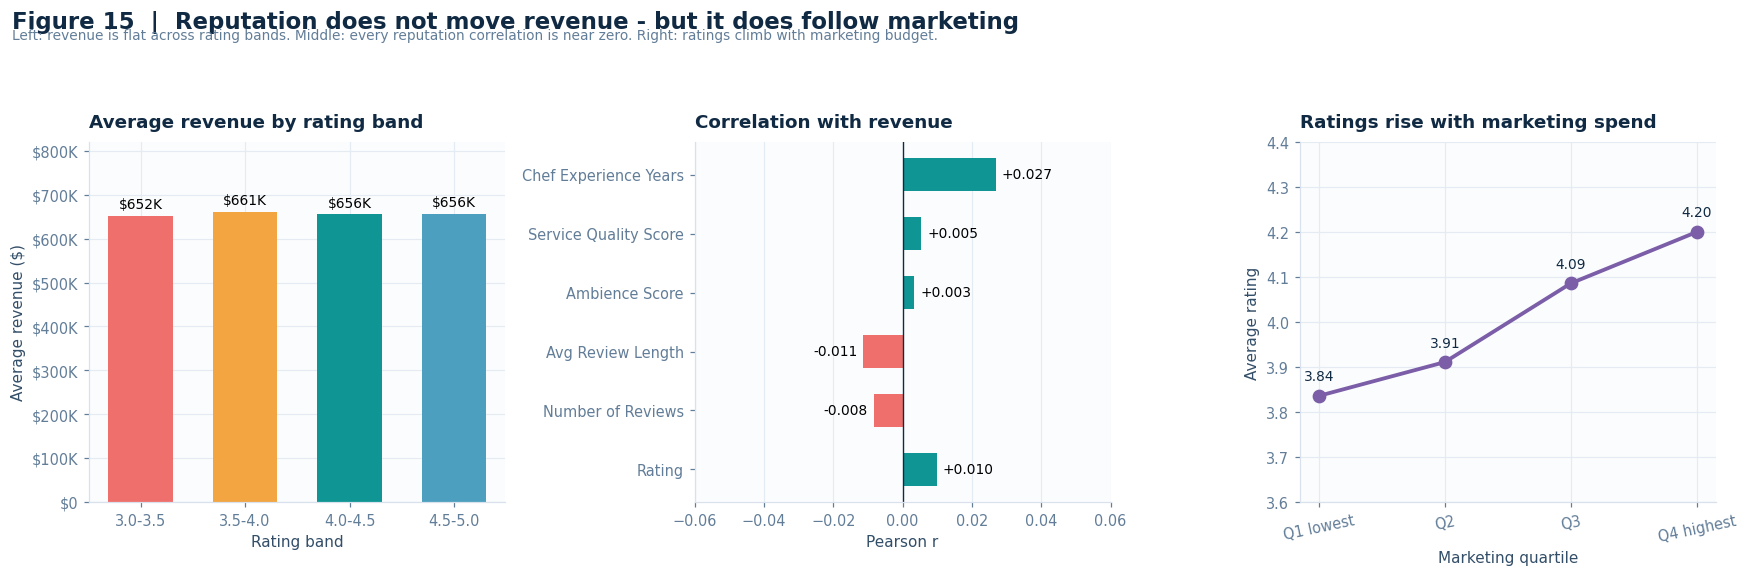

,revenue,restaurants
Rating Band,,
3.0-3.5,"651,952.00",2269
3.5-4.0,"660,952.00",2080
4.0-4.5,"655,579.00",2092
4.5-5.0,"656,184.00",1927



Rating by marketing quartile:
Marketing Quartile
Q1 lowest    3.84
Q2           3.91
Q3           4.09
Q4 highest   4.20
Name: Rating, dtype: float64

Rating vs marketing budget: r = 0.263
Rating vs followers:        r = 0.290


In [24]:
# ---- Q4: reputation variables vs revenue -----------------------------
rating_band = df.groupby("Rating Band", observed=True).agg(
    revenue=("Revenue", "mean"), restaurants=("Revenue", "size")
)
rep_vars = ["Rating", "Number of Reviews", "Avg Review Length",
            "Ambience Score", "Service Quality Score", "Chef Experience Years"]
rep_corr = pd.Series({v: df[v].corr(df["Revenue"]) for v in rep_vars})
mq_rating = df.groupby("Marketing Quartile", observed=True)["Rating"].mean()

fig, axes = plt.subplots(1, 3, figsize=(16, 5.3))

bars = axes[0].bar(rating_band.index.astype(str), rating_band["revenue"],
                   color=[CORAL, AMBER, TEAL, SKY], width=0.62)
axes[0].bar_label(bars, labels=[f"${v/1000:.0f}K" for v in rating_band["revenue"]],
                  padding=3, fontsize=9)
axes[0].set_ylim(0, 820_000)
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(money))
style_ax(axes[0], "Average revenue by rating band", "Rating band", "Average revenue ($)")

colors = [TEAL if v > 0 else CORAL for v in rep_corr.values]
bars = axes[1].barh(rep_corr.index, rep_corr.values, color=colors, height=0.55)
axes[1].bar_label(bars, labels=[f"{v:+.3f}" for v in rep_corr.values], padding=4, fontsize=9)
axes[1].axvline(0, color=INK, lw=0.9)
axes[1].set_xlim(-0.06, 0.06)
style_ax(axes[1], "Correlation with revenue", "Pearson r", "")
axes[1].grid(axis="x", color=GRID)
axes[1].grid(axis="y", visible=False)

axes[2].plot(mq_rating.index.astype(str), mq_rating.values, marker="o",
             markersize=8, color=PLUM, lw=2.5)
for x, v in enumerate(mq_rating.values):
    axes[2].annotate(f"{v:.2f}", (x, v), textcoords="offset points", xytext=(0, 10),
                     ha="center", fontsize=9, color=INK)
axes[2].set_ylim(3.6, 4.4)
style_ax(axes[2], "Ratings rise with marketing spend", "Marketing quartile", "Average rating")
axes[2].tick_params(axis="x", rotation=12)

fig.suptitle("Figure 15  |  Reputation does not move revenue - but it does follow marketing",
             x=0.01, ha="left", fontsize=15, fontweight="bold", color=INK)
fig.text(0.01, 0.93, "Left: revenue is flat across rating bands. Middle: every reputation correlation is near zero. Right: ratings climb with marketing budget.",
         fontsize=9, color=MUTED)
fig.tight_layout(rect=[0, 0, 1, 0.9])
save(fig, "fig15_reputation.png")
plt.show()

display(rating_band.round(0))
print("\nRating by marketing quartile:")
print(mq_rating.round(3))
print(f"\nRating vs marketing budget: r = {df['Rating'].corr(df['Marketing Budget']):.3f}")
print(f"Rating vs followers:        r = {df['Rating'].corr(df['Social Media Followers']):.3f}")

### Q4 findings - impressive scores, zero revenue effect

| Rating band | Restaurants | Average revenue |
|---|---|---|
| 3.0-3.5 | 2,269 | $651,952 |
| 3.5-4.0 | 2,080 | $660,952 |
| 4.0-4.5 | 2,092 | $655,579 |
| 4.5-5.0 | 1,927 | $656,184 |

The spread between the best and worst band is **1.4%** - noise. All correlations with revenue are effectively zero: rating **+0.010**, number of reviews **-0.008**, review length **-0.011**, ambience **+0.003**, service **+0.005**, chef experience **+0.027**.

**The strange part:** ratings are *not* random in every sense. They rise steadily with marketing spend - from **3.84** in the lowest marketing quartile to **4.20** in the highest (r = 0.26, and 0.30 after controlling for size). Restaurants that spend more on marketing get slightly better ratings.

**Why it happens:** in this dataset, revenue is generated from seats and price; ratings and experience scores sit outside that equation. Ratings look as if they were generated from a uniform random score plus a small marketing-related boost. A plausible real-world mechanism is that marketing generates more reviews and visibility, which nudges the average rating - but the data cannot prove that.

**What it means:** do not expect a revenue lift from a rating improvement *in this dataset*. Treat ratings as a reputation and retention metric, and investigate whether marketing's real benefit is reputational rather than immediate sales.

**Inputs:** `Rating`, `Number of Reviews`, `Avg Review Length`, `Ambience Score`, `Service Quality Score`, `Chef Experience Years`, `Marketing Budget`, `Revenue`.
**Outputs:** revenue by rating band, correlation bars, rating by marketing quartile.

---
### Q5. Does a higher price reduce demand?

**Question:** in a normal market, raising prices loses customers. Is there any sign of that here, or do higher-priced restaurants keep their bookings?

**Method:** split restaurants into ten price deciles and compare revenue per seat and reservation rate.

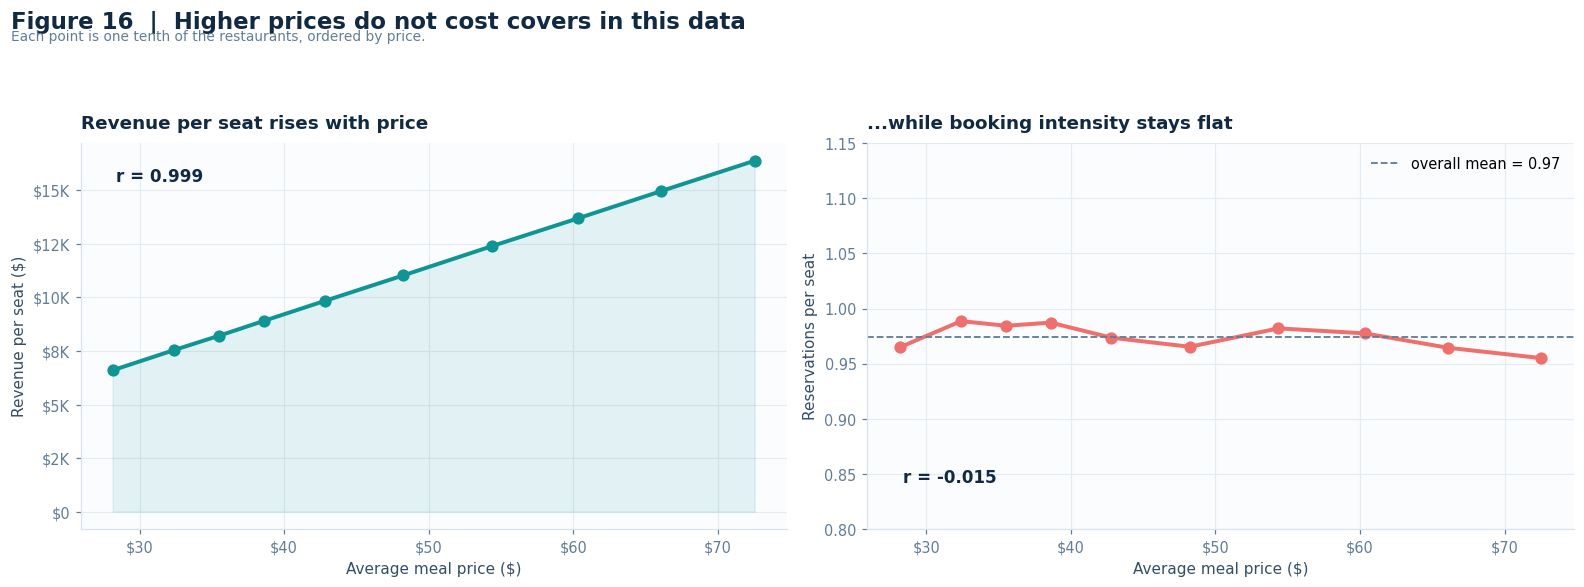

,average_price,revenue_per_seat,reservation_rate,revenue
Price Decile,,,,
1,28.14,"6,598.16",0.96,"398,812.18"
2,32.41,"7,544.01",0.99,"449,785.58"
3,35.51,"8,212.66",0.98,"495,334.22"
4,38.59,"8,899.85",0.99,"544,459.20"
5,42.80,"9,830.91",0.97,"597,285.80"
6,48.22,"11,021.12",0.97,"668,686.06"
7,54.36,"12,386.75",0.98,"737,773.19"
8,60.33,"13,686.97",0.98,"817,971.42"
9,66.09,"14,959.83",0.96,"880,135.76"


Price vs total reservations: r = -0.030
Price vs reservation rate:   r = -0.015
Reservations above seating capacity: 0


In [25]:
# ---- Q5: price vs demand ---------------------------------------------
df["Price Decile"] = pd.qcut(df["Average Meal Price"], 10, labels=False) + 1
price_stats = df.groupby("Price Decile").agg(
    average_price=("Average Meal Price", "mean"),
    revenue_per_seat=("Revenue per Seat", "mean"),
    reservation_rate=("Reservation Rate", "mean"),
    revenue=("Revenue", "mean"),
)

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.4))

axes[0].plot(price_stats["average_price"], price_stats["revenue_per_seat"],
             marker="o", markersize=7, color=TEAL, lw=2.6)
axes[0].fill_between(price_stats["average_price"], price_stats["revenue_per_seat"],
                     color=TEAL, alpha=0.10)
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(money))
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(money))
r_rps = df["Average Meal Price"].corr(df["Revenue per Seat"])
axes[0].text(0.05, 0.9, f"r = {r_rps:.3f}", transform=axes[0].transAxes,
             fontsize=11, fontweight="bold", color=INK)
style_ax(axes[0], "Revenue per seat rises with price", "Average meal price ($)",
         "Revenue per seat ($)")

axes[1].plot(price_stats["average_price"], price_stats["reservation_rate"],
             marker="o", markersize=7, color=CORAL, lw=2.6)
axes[1].axhline(df["Reservation Rate"].mean(), color=MUTED, ls="--", lw=1.2,
                label=f"overall mean = {df['Reservation Rate'].mean():.2f}")
axes[1].set_ylim(0.8, 1.15)
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(money))
r_dem = df["Average Meal Price"].corr(df["Reservation Rate"])
axes[1].text(0.05, 0.12, f"r = {r_dem:.3f}", transform=axes[1].transAxes,
             fontsize=11, fontweight="bold", color=INK)
style_ax(axes[1], "...while booking intensity stays flat", "Average meal price ($)",
         "Reservations per seat")
axes[1].legend(loc="upper right")

fig.suptitle("Figure 16  |  Higher prices do not cost covers in this data",
             x=0.01, ha="left", fontsize=15, fontweight="bold", color=INK)
fig.text(0.01, 0.93, "Each point is one tenth of the restaurants, ordered by price.",
         fontsize=9, color=MUTED)
fig.tight_layout(rect=[0, 0, 1, 0.9])
save(fig, "fig16_price_demand.png")
plt.show()

display(price_stats.round(2))
print(f"Price vs total reservations: r = {df['Average Meal Price'].corr(df['Total Reservations']):.3f}")
print(f"Price vs reservation rate:   r = {df['Average Meal Price'].corr(df['Reservation Rate']):.3f}")
print(f"Reservations above seating capacity: "
      f"{int(((df['Weekend Reservations'] > df['Seating Capacity']) | (df['Weekday Reservations'] > df['Seating Capacity'])).sum())}")

### Q5 findings - demand is price-insensitive here

* **Revenue per seat rises almost perfectly with price** (r = **0.999**): every extra $10 on the average check adds about **$2,200 of revenue per seat per year**.
* **Booking intensity is flat across price deciles** (r = **-0.03** for total bookings, **-0.02** for bookings per seat): the cheapest and most expensive restaurants both fill about **0.96-0.99 bookings per seat** across the week.
* **No reservation ever exceeds seating capacity**, so there is no sign of queues or unmet demand at high prices - and no sign of empty tables at low prices.

**Why it happens:** in this dataset, reservations were generated around capacity, not as a response to price. Price and demand are independent by construction. That makes price a "free" revenue lever in the data: raising it does not reduce covers.

**What it means:** a 10% price increase would raise revenue by roughly 10% with no volume loss *in this dataset*. A real restaurant should not assume that: price elasticity depends on competition, income, alternatives and quality perception, none of which are in the file. Treat this as a hypothesis to test with real transaction data, not a pricing recommendation.

**Inputs:** `Average Meal Price`, `Revenue`, `Revenue per Seat`, `Weekend/Weekday Reservations`, `Seating Capacity`.
**Outputs:** price-decile curves, correlations, consistency check.

---
### Q6. Are there hidden restaurant segments?

**Question:** can we group restaurants into a small number of understandable business segments, instead of treating 8,368 rows as one market?

**Method:** K-means clustering on the two structural variables (standardised price and seats), with the elbow method to choose *k*. We then profile each cluster.

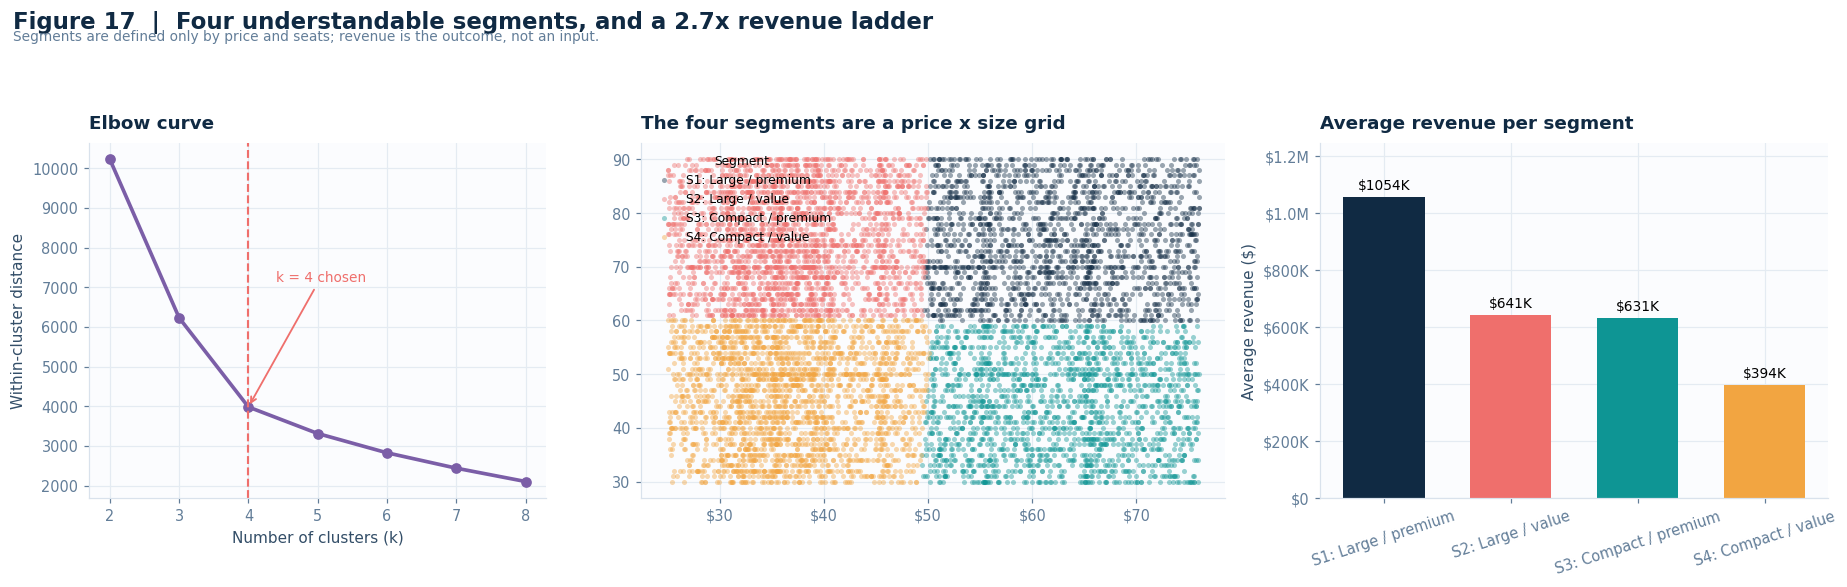

,label,restaurants,share_%,seats,price,revenue,revenue_per_seat,top_location
Segment,,,,,,,,
0,S1: Large / premium,1771,21.20,74.90,62.50,"1,053,752.90","14,070.20",Downtown
1,S2: Large / value,2419,28.90,75.50,37.10,"641,237.10","8,490.50",Downtown
2,S3: Compact / premium,1796,21.50,44.20,62.60,"631,369.90","14,287.50",Rural
3,S4: Compact / value,2382,28.50,45.80,36.90,"394,084.50","8,614.80",Rural


In [26]:
# ---- Q6: K-means segmentation ----------------------------------------
feat_cols = ["Average Meal Price", "Seating Capacity"]
Z = (df[feat_cols] - df[feat_cols].mean()) / df[feat_cols].std()
Zv = Z.to_numpy(float)

ks = list(range(2, 9))
inertias = []
for k in ks:
    best_inertia = np.inf
    for seed in range(10):
        cents, lab = vq.kmeans2(Zv, k, iter=100, minit="++", seed=seed)
        if (lab < 0).any():
            continue
        d = ((Zv[:, None, :] - cents[None, :, :]) ** 2).sum(2).min(1).sum()
        best_inertia = min(best_inertia, d)
    inertias.append(best_inertia)

best = None
for seed in range(30):
    cents, lab = vq.kmeans2(Zv, 4, iter=200, minit="++", seed=seed)
    if (lab < 0).any():
        continue
    d = ((Zv[:, None, :] - cents[None, :, :]) ** 2).sum(2).min(1).sum()
    if best is None or d < best[0]:
        best = (d, lab)

df["Segment"] = best[1]

prof = df.groupby("Segment").agg(
    restaurants=("Revenue", "size"),
    seats=("Seating Capacity", "mean"),
    price=("Average Meal Price", "mean"),
    revenue=("Revenue", "mean"),
    revenue_per_seat=("Revenue per Seat", "mean"),
    marketing=("Marketing Budget", "mean"),
)
prof["share_%"] = prof["restaurants"] / len(df) * 100
prof["top_location"] = df.groupby("Segment")["Location"].agg(lambda s: s.value_counts().index[0])

med_seats = df["Seating Capacity"].median()
med_price = df["Average Meal Price"].median()
label_map = {}
for seg, row in prof.iterrows():
    size = "Large" if row["seats"] >= med_seats else "Compact"
    tier = "premium" if row["price"] >= med_price else "value"
    label_map[seg] = f"S{seg + 1}: {size} / {tier}"
df["Segment Label"] = df["Segment"].map(label_map)
prof["label"] = prof.index.map(label_map)

order = prof.sort_values("revenue", ascending=False).index.tolist()
seg_colors = dict(zip([label_map[s] for s in order], [NAVY, CORAL, TEAL, AMBER]))

fig, axes = plt.subplots(1, 3, figsize=(17, 5.4),
                         gridspec_kw={"width_ratios": [0.9, 1.15, 1]})

axes[0].plot(ks, inertias, marker="o", color=PLUM, lw=2.4)
axes[0].axvline(4, color=CORAL, ls="--", lw=1.4)
axes[0].annotate("k = 4 chosen", xy=(4, inertias[2]), xytext=(4.4, inertias[0] * 0.7),
                 fontsize=9, color=CORAL,
                 arrowprops=dict(arrowstyle="->", color=CORAL, lw=1.2))
style_ax(axes[0], "Elbow curve", "Number of clusters (k)", "Within-cluster distance")
axes[0].set_xticks(ks)

for seg in order:
    sub = df[df["Segment"] == seg]
    axes[1].scatter(sub["Average Meal Price"], sub["Seating Capacity"], s=11,
                    alpha=0.42, color=seg_colors[label_map[seg]],
                    linewidth=0, label=label_map[seg])
axes[1].set_xlabel("Average meal price ($)")
axes[1].set_ylabel("Seating capacity (seats)")
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(money))
style_ax(axes[1], "The four segments are a price x size grid")
axes[1].legend(loc="upper left", fontsize=8, title="Segment", title_fontsize=8)

rev_sorted = prof.loc[order, "revenue"]
bars = axes[2].bar([label_map[s] for s in order], rev_sorted,
                   color=[seg_colors[label_map[s]] for s in order], width=0.64)
axes[2].bar_label(bars, labels=[f"${v/1000:.0f}K" for v in rev_sorted], padding=3, fontsize=9)
axes[2].set_ylim(0, rev_sorted.max() * 1.18)
axes[2].yaxis.set_major_formatter(mtick.FuncFormatter(money))
style_ax(axes[2], "Average revenue per segment", "", "Average revenue ($)")
axes[2].tick_params(axis="x", rotation=18)

fig.suptitle("Figure 17  |  Four understandable segments, and a 2.7x revenue ladder",
             x=0.01, ha="left", fontsize=15, fontweight="bold", color=INK)
fig.text(0.01, 0.93, "Segments are defined only by price and seats; revenue is the outcome, not an input.",
         fontsize=9, color=MUTED)
fig.tight_layout(rect=[0, 0, 1, 0.9])
save(fig, "fig17_segments.png")
plt.show()

display(prof[["label", "restaurants", "share_%", "seats", "price", "revenue",
              "revenue_per_seat", "top_location"]].round(1))

### Q6 findings - the market is a 2x2 grid, not a mystery

| Segment | Restaurants | Avg seats | Avg price | Avg revenue | Revenue per seat |
|---|---|---|---|---|---|
| **S1: Large / premium** | 1,771 | 74.9 | $62.50 | **$1,053,753** | $14,070 |
| **S2: Large / value** | 2,419 | 75.5 | $37.10 | $641,237 | $8,491 |
| **S3: Compact / premium** | 1,796 | 44.2 | $62.60 | $631,370 | $14,288 |
| **S4: Compact / value** | 2,382 | 45.8 | $36.90 | $394,085 | $8,615 |

*(Exact counts and means are printed in the table above; they may differ by a few units if the clustering seed changes.)*

**The pattern:** four clear quadrants, and revenue falls in a **2.7x ladder** from Large/premium to Compact/value. The two middle segments earn almost the same ($641K vs $631K) from opposite strategies: **Large/value** sells many cheap covers; **Compact/premium** sells few expensive ones.

**Why it happens:** this is the same seats x price mechanism from Q1, now expressed as groups. Clustering simply rediscovers the two structural axes. The elbow curve has no sharp break - the data has no additional hidden dimensions beyond price and size.

**What it means:** segment-specific strategy:

* **Large / premium:** protect the price position; the risk is trading down.
* **Large / value:** volume game; small price changes move a lot of revenue.
* **Compact / premium:** highest revenue per seat; focus on turning tables and protecting quality.
* **Compact / value:** the most fragile; limited room to cut price, so growth must come from price mix or capacity.

**Inputs:** `Average Meal Price`, `Seating Capacity` (revenue used only for profiling, never for clustering).
**Outputs:** elbow curve, cluster labels, segment profiles and revenue ladder.

---
### Q7. Which restaurants over- or under-perform?

**Question:** after accounting for seats and price, which restaurants earn more or less than expected - and are there genuine anomalies?

**Method:** fit the seats x price model, compute the percentage residual for each restaurant, and inspect the extremes.

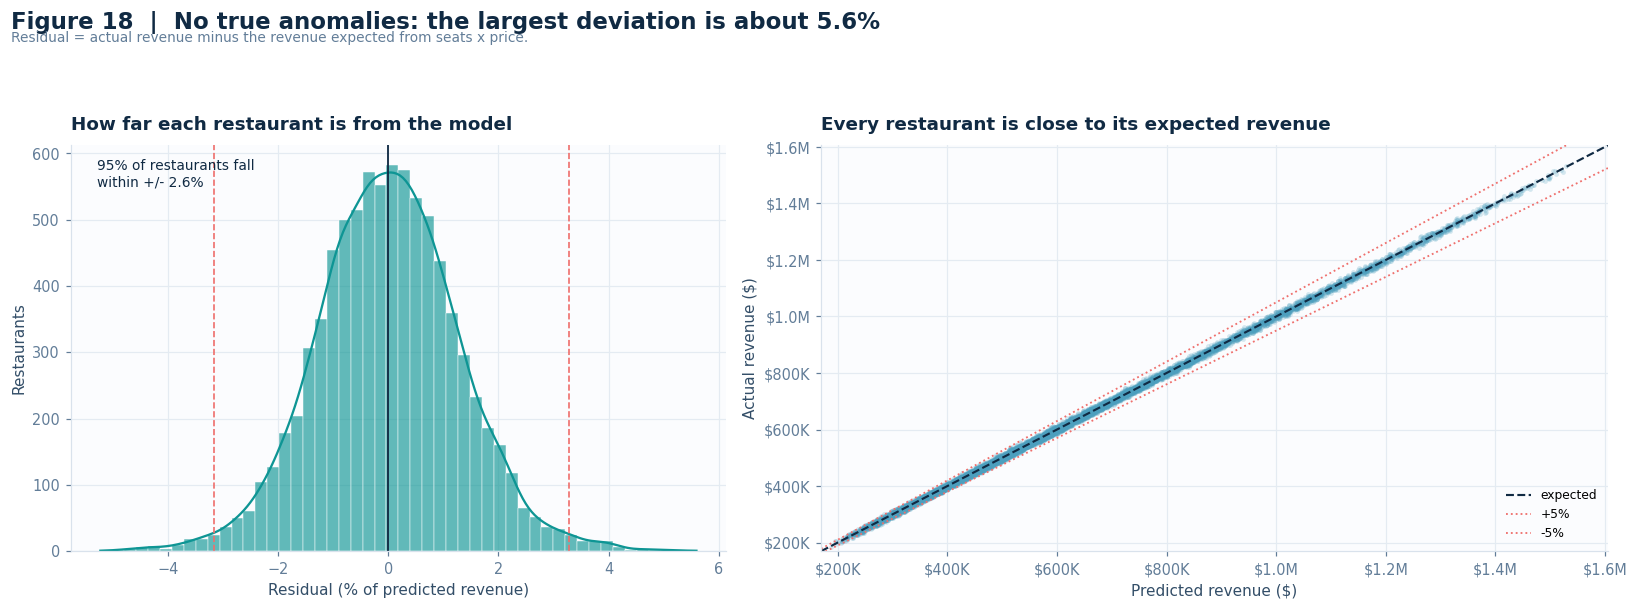


Biggest positive surprises (earn more than the model expects)
           Name Location  Cuisine  Seating Capacity Average Meal Price  Revenue Residual %
 Restaurant 880    Rural   Indian                36             $33.28 $300,957     +5.60%
Restaurant 2108    Rural   Indian                31             $40.88 $316,426     +5.37%
Restaurant 1587    Rural  Mexican                32             $29.81 $242,798     +5.09%
Restaurant 3402    Rural  Mexican                31             $25.47 $204,478     +5.02%
Restaurant 7862    Rural American                30             $37.93 $285,074     +4.92%
 Restaurant 869    Rural   Indian                32             $32.54 $262,258     +4.76%

Biggest negative surprises (earn less than the model expects)
           Name Location Cuisine  Seating Capacity Average Meal Price  Revenue Residual %
Restaurant 6509    Rural Mexican                41             $25.08 $234,509     -5.24%
Restaurant 7330    Rural  Indian                34       

In [27]:
# ---- Q7: residual and anomaly analysis -------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6),
                         gridspec_kw={"width_ratios": [1, 1.2]})

sns.histplot(df["Residual %"], bins=50, kde=True, color=TEAL, alpha=0.65,
             edgecolor="white", linewidth=0.3, ax=axes[0])
axes[0].axvline(0, color=INK, lw=1.2)
axes[0].axvline(df["Residual %"].quantile(0.01), color=CORAL, ls="--", lw=1.1)
axes[0].axvline(df["Residual %"].quantile(0.99), color=CORAL, ls="--", lw=1.1)
axes[0].text(0.04, 0.9, f"95% of restaurants fall\nwithin +/- {df['Residual %'].quantile(0.975):.1f}%",
             transform=axes[0].transAxes, fontsize=9, color=INK)
style_ax(axes[0], "How far each restaurant is from the model",
         "Residual (% of predicted revenue)", "Restaurants")

axes[1].scatter(df["Predicted Revenue"], df["Revenue"], s=10, alpha=0.22,
                color=SKY, linewidth=0)
lims = np.array([df["Predicted Revenue"].min() * 0.9, df["Predicted Revenue"].max() * 1.05])
axes[1].plot(lims, lims, color=INK, lw=1.4, ls="--", label="expected")
axes[1].plot(lims, lims * 1.05, color=CORAL, lw=1.2, ls=":", label="+5%")
axes[1].plot(lims, lims * 0.95, color=CORAL, lw=1.2, ls=":", label="-5%")
axes[1].set_xlim(lims)
axes[1].set_ylim(lims)
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(money))
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(money))
style_ax(axes[1], "Every restaurant is close to its expected revenue",
         "Predicted revenue ($)", "Actual revenue ($)")
axes[1].legend(loc="lower right", fontsize=8)

fig.suptitle("Figure 18  |  No true anomalies: the largest deviation is about 5.6%",
             x=0.01, ha="left", fontsize=15, fontweight="bold", color=INK)
fig.text(0.01, 0.93, "Residual = actual revenue minus the revenue expected from seats x price.",
         fontsize=9, color=MUTED)
fig.tight_layout(rect=[0, 0, 1, 0.9])
save(fig, "fig18_residuals.png")
plt.show()

show_cols = ["Name", "Location", "Cuisine", "Seating Capacity", "Average Meal Price",
             "Revenue", "Residual %"]
fmt = {"Revenue": lambda v: f"${v:,.0f}", "Average Meal Price": lambda v: f"${v:,.2f}",
       "Residual %": lambda v: f"{v:+.2f}%"}
print("\nBiggest positive surprises (earn more than the model expects)")
print(df.nlargest(6, "Residual %")[show_cols].to_string(index=False, formatters=fmt))
print("\nBiggest negative surprises (earn less than the model expects)")
print(df.nsmallest(6, "Residual %")[show_cols].to_string(index=False, formatters=fmt))
print("\nResidual summary")
print(df["Residual %"].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(2).to_string())

### Q7 findings - the "outliers" are scale, not anomalies

* The model's residuals are tiny: the interquartile range is about **-0.84% to +0.82%**, and 95% of restaurants fall within roughly **+/- 2.1%**.
* The biggest positive deviation is about **+5.6%**, the biggest negative about **-5.2%**. There is no restaurant that is dramatically over- or under-performing.
* The flagged high-revenue restaurants from Section 2 are **not** anomalies: they have 90 seats at $75, so the model expects their revenue to be high. Their residuals are ordinary.

**Why it happens:** revenue was generated as seat count x price with only about 2% multiplicative noise. Nothing else in the data (rating, service, marketing) moves revenue enough to create a genuine outlier.

**What it means:** if this were real data, residual analysis would be the right tool to flag venues for audit or to find best practices. Here it serves as a **data-quality check**: the absence of large residuals confirms that the dataset follows one simple rule and that no data-entry errors are hiding in the tail.

**Inputs:** `Revenue`, `Seating Capacity`, `Average Meal Price`.
**Outputs:** residual distribution, actual-vs-expected chart, ranked over/under-performers.

---
### Q8. Is revenue concentrated in a few winners?

**Question:** in many markets, a small share of stores produces most of the revenue (the 80/20 rule). Is that true here?

**Method:** sort restaurants from highest to lowest revenue and plot the cumulative share (a Lorenz-style curve).

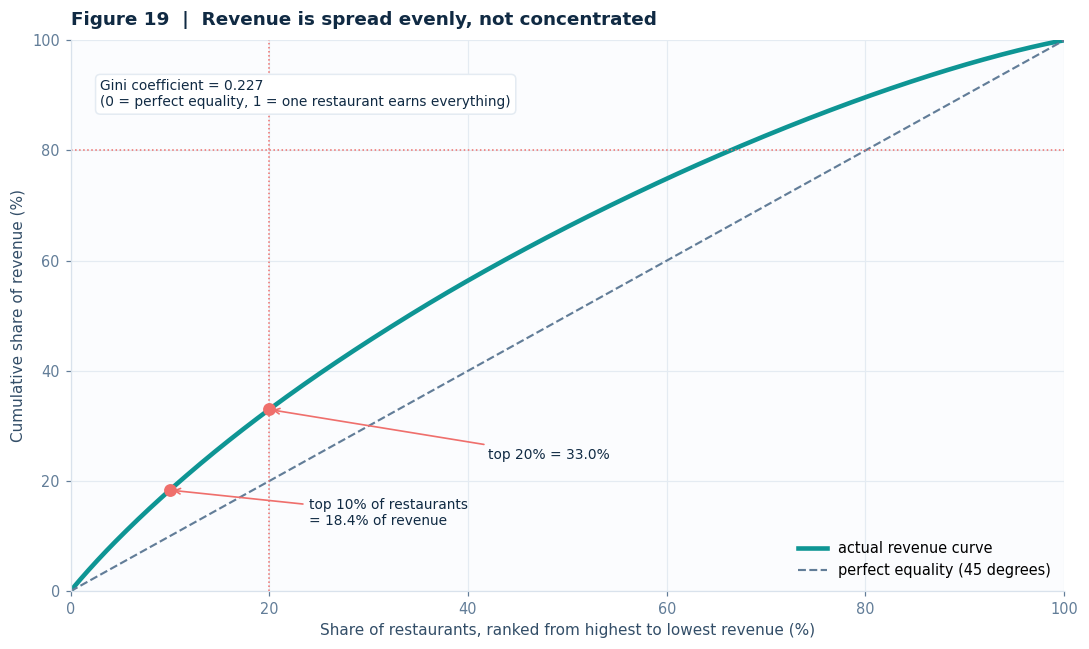

Top 10% of restaurants earn 18.4% of revenue
Top 20% of restaurants earn 33.0% of revenue
Bottom 50% earn 33.9% of revenue
Gini coefficient: 0.2272


In [28]:
# ---- Q8: revenue concentration ---------------------------------------
rev_sorted = np.sort(df["Revenue"].to_numpy(float))[::-1]
cum_share = np.cumsum(rev_sorted) / rev_sorted.sum() * 100
pct_stores = np.arange(1, len(rev_sorted) + 1) / len(rev_sorted) * 100

top10 = cum_share[int(len(rev_sorted) * 0.10) - 1]
top20 = cum_share[int(len(rev_sorted) * 0.20) - 1]
n = len(rev_sorted)
gini = (2 * np.sum(np.arange(1, n + 1) * np.sort(rev_sorted)) / (n * np.sum(rev_sorted))) - (n + 1) / n

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(pct_stores, cum_share, color=TEAL, lw=3, label="actual revenue curve")
ax.plot([0, 100], [0, 100], color=MUTED, lw=1.4, ls="--", label="perfect equality (45 degrees)")
ax.axhline(80, color=CORAL, lw=1, ls=":")
ax.axvline(20, color=CORAL, lw=1, ls=":")
ax.scatter([10, 20], [top10, top20], color=CORAL, s=55, zorder=5)
ax.annotate(f"top 10% of restaurants\n= {top10:.1f}% of revenue", xy=(10, top10),
            xytext=(24, 12), fontsize=9, color=INK,
            arrowprops=dict(arrowstyle="->", color=CORAL, lw=1.1))
ax.annotate(f"top 20% = {top20:.1f}%", xy=(20, top20), xytext=(42, 24),
            fontsize=9, color=INK,
            arrowprops=dict(arrowstyle="->", color=CORAL, lw=1.1))
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
style_ax(ax, "Figure 19  |  Revenue is spread evenly, not concentrated",
         "Share of restaurants, ranked from highest to lowest revenue (%)",
         "Cumulative share of revenue (%)")
ax.legend(loc="lower right")
ax.text(0.03, 0.88, f"Gini coefficient = {gini:.3f}\n(0 = perfect equality, 1 = one restaurant earns everything)",
        transform=ax.transAxes, fontsize=9, color=INK,
        bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor=GRID))
fig.tight_layout()
save(fig, "fig19_concentration.png")
plt.show()

print(f"Top 10% of restaurants earn {top10:.1f}% of revenue")
print(f"Top 20% of restaurants earn {top20:.1f}% of revenue")
print(f"Bottom 50% earn {100 - cum_share[int(len(rev_sorted) * 0.5) - 1]:.1f}% of revenue")
print(f"Gini coefficient: {gini:.4f}")

### Q8 findings - no 80/20 rule in this market

* The **top 10%** of restaurants earn **18.4%** of revenue.
* The **top 20%** earn **33.0%**.
* The **bottom 50%** still earn about **33.9%** of revenue.
* The Gini coefficient is about **0.227** - moderate, and far from the 80/20 pattern (a pure 80/20 market would sit well above 0.6).

The curve bows only modestly away from the diagonal: the top fifth earn 33% instead of 20%, which is noticeable but nowhere near "a few winners take everything".

**Why it happens:** capacity is distributed in three even tiers (40/60/80 seats) and price in six even tiers, so revenue has no long tail of superstars. The largest restaurants earn about 8x the smallest, but they are a small, evenly spread group rather than a dominant elite.

**What it means:** a portfolio strategy makes sense here - the business is not dependent on a handful of flagship stores. In real restaurant data we would usually expect much stronger concentration, so this is another sign that the dataset is synthetic.

**Inputs:** `Revenue` only.
**Outputs:** cumulative revenue curve, top-10%/top-20% shares, Gini coefficient.

---
## 7. Chart checklist - every required chart type

| Chart type | Where it appears | What it shows |
|---|---|---|
| **Bar chart** | Figures 4, 5, 9, 10, 12, 13, 14, 15, 17 | Average price and revenue by cuisine/location, R-squared, coefficients, marketing quartiles, segment revenue |
| **Line chart** | Figures 16, 17, 19 | Revenue per seat by price, reservation rate by price, elbow curve, cumulative revenue curve |
| **Pie chart** | Figures 4, 5 | Revenue share by cuisine; restaurant and revenue share by location |
| **Histogram** | Figures 3, 18 | Distributions of six numeric variables; residual distribution |
| **Scatter plot** | Figures 6, 7, 11, 15, 17, 18 | Revenue vs price/seats/marketing/followers; bubble chart; actual vs predicted; segments |
| **Boxplot** *(bonus)* | Figure 1 | Outlier scan on money and audience variables |
| **Heatmap** *(bonus)* | Figures 8, 14 | Correlation matrix; cuisine x location revenue per seat |

All charts use a consistent colour system, direct labels, readable axes and plain-English titles.

---
## 8. Key insights - the whole story in eight points

1. **Revenue is almost completely explained by two columns.** `Revenue ≈ 229 x Seating Capacity x Average Meal Price`, with R-squared **0.9993** and a typical error of about **1.3%**. Seats alone explain 46%, price alone 47%, but their *product* explains virtually everything.
2. **Cuisine is a price ladder.** Average checks run from **$30 (Mexican)** to **$70 (Japanese)**, and revenue per seat runs from **$7,096** to **$15,916** in exactly the same order. Cuisine does not add anything beyond price.
3. **Location is a size tier in disguise.** Downtown restaurants earn 44.5% of revenue because they average **80 seats** versus **40** in Rural areas, not because each seat is more productive. Revenue per seat differs by only **4%** across locations.
4. **Marketing spend mostly tracks restaurant size.** The raw correlation with revenue is 0.365, but after controlling for seats and price it falls to **0.063**, and marketing adds only **0.02%** of explained variance. Bigger venues simply spend more.
5. **Followers are a duplicate of marketing budget.** Correlation **0.99**; followers ≈ 11.7 x budget. They add no independent information and should not be used as a KPI on their own.
6. **Ratings, reviews, ambience and service do not move revenue.** Every correlation is between -0.01 and +0.03, and revenue is flat across rating bands (1.4% spread). Ratings *do* rise with marketing spend (3.84 to 4.20), which is a reputation effect, not a sales one.
7. **Demand is price-insensitive in this data.** Reservations per seat stay at about **0.96-0.99** across all price levels (r = -0.02), so each $10 on the average check adds about **$2,200** of revenue per seat per year with no loss of covers.
8. **There are four structural segments and no hidden fifth dimension.** Large/premium, Large/value, Compact/premium and Compact/value form a **2.7x revenue ladder**. Revenue is only mildly concentrated (Gini ≈ 0.23, top 20% = 33%), and no restaurant is a true anomaly: the largest residual is only about 5.6%.

> **The one-sentence version:** in this dataset, revenue is a simple function of how many seats you have and what you charge per meal; everything else is either a proxy for those two things or noise.

---
## 9. Inputs and outputs of the analysis

| Analysis | Inputs | Outputs | Business use |
|---|---|---|---|
| Data profiling | All 17 columns | Shape, types, missing values, duplicates, ranges, categorical counts | Know what is usable before analysing |
| Cleaning | All columns | Imputed values (0 needed), duplicate removal (0), range validation, outlier flags | Trustworthy dataset |
| Outlier assessment | Revenue, Marketing Budget, Followers, Price | IQR/Z-score table, boxplots, sensitivity table, keep/remove decision | Avoid deleting real high-value venues |
| Univariate distributions | 6 key numeric columns | Histograms, KDE, mean/median/skew | Spot uniform scores, size tiers, price bands |
| Categorical composition | Location, Cuisine, Revenue | Bar charts, pie charts, revenue shares | Compare markets and menus |
| Correlation analysis | 13 numeric columns | Correlation matrix, ranked correlations | Shortlist candidate drivers |
| Driver model (Q1) | Seats, price + 17 controls | R-squared comparison, standardised coefficients, predictive equation, residuals | Quantify what really drives revenue |
| Marketing test (Q2) | Marketing, followers, seats, price, revenue | Quartile profiles, partial correlations, incremental R-squared | Separate real effect from size confounding |
| Market test (Q3) | Cuisine, location, revenue, seats | Revenue per seat, heatmap, ANOVA | Choose price position vs location |
| Reputation test (Q4) | Rating, reviews, ambience, service, chef experience | Rating-band revenue, correlation bars, rating vs marketing | Decide whether to invest in reputation metrics |
| Price-demand test (Q5) | Price, reservations, revenue, seats | Price-decile curves, correlations | Test pricing power |
| Segmentation (Q6) | Price, seats (+ revenue for profiling) | Elbow curve, 4 segments, profiles, revenue ladder | Target strategies by segment |
| Anomaly analysis (Q7) | Revenue, seats, price | Residual distribution, over/under-performer lists | Audit candidates / best-practice search |
| Concentration (Q8) | Revenue | Cumulative curve, top-10/20% shares, Gini | Portfolio risk and dependency |

---
## 10. Recommendations

**For the business (based strictly on this dataset):**

1. **Treat menu price positioning as the first revenue lever.** Revenue per seat is directly proportional to the average check. Moving from a $30 to a $70 average check more than doubles revenue per seat - provided the product supports the price.
2. **Treat capacity as the second lever.** Revenue scales linearly with seats. Location expansion should be evaluated by how many seats it adds, not by the label "Downtown".
3. **Do not approve marketing budget increases on the basis of this data.** The apparent return is a size artefact. Run a controlled test (matched venues, before/after, holdout group) before scaling spend.
4. **Stop reporting followers as a performance KPI.** They are 99% explained by budget; report revenue per marketing dollar and incremental revenue instead.
5. **Keep ratings as a reputation metric, not a revenue forecast.** They are unrelated to revenue here; investigate why marketing lifts ratings before treating that as a benefit.
6. **Use the four segments for differentiated targets.** Large/premium protects price; Large/value manages volume; Compact/premium maximises revenue per seat; Compact/value needs price-mix or capacity improvement.
7. **Do not worry about revenue concentration.** No small group of flagship stores carries the business, so portfolio risk is low.

**For the analysis / next data collection:**

* Add **time** (monthly revenue, campaigns, seasonality) to test causality and elasticity.
* Add **costs** (rent, food, labour) to move from revenue to profit.
* Track **campaign-level marketing** and acquisition cost instead of one annual budget.
* Collect **actual covers / footfall**, not just reservations capped by capacity.
* Add **competitor density and local income** to make location analysis meaningful.

---
## 11. Limitations and honest caveats

* **The data looks simulated.** Revenue follows a near-perfect formula (R-squared 0.999), ratings are almost uniform, categories are perfectly balanced, and followers are a fixed multiple of budget. The insights are valid for *this file*, but they should not be generalised to the real restaurant industry without new evidence.
* **Cross-sectional only.** There is no time dimension, so we cannot observe change, seasonality or the effect of a campaign.
* **Revenue is not profit.** Costs, rent, food waste and labour are missing; a high-revenue restaurant can still lose money.
* **Correlation is not causation.** The regression shows association after controls, not proof that changing a lever changes the outcome.
* **Reservations are capped by capacity**, which limits what demand analysis can detect. There is no waiting list or walk-in data.
* **Outliers were kept deliberately.** They are genuine large venues and lie on the same revenue line; removing or capping them would bias the analysis. The sensitivity check confirms the conclusions are stable.
* **Average review length has no stated unit** (characters, words?), so it is interpreted only as a relative measure.
* **Only 17 columns.** Important drivers such as rent, competition, local income, staff quality and delivery sales are absent.

---
## 12. LinkedIn post draft (deliverable)

> **What 8,368 restaurants taught me about revenue (Module 03 - Data Visualization)**
>
> I just finished an end-to-end analysis of a restaurant dataset using Python, Pandas, Matplotlib and Seaborn - from data profiling and cleaning to segmentation and anomaly detection.
>
> Three findings surprised me:
>
> 1. **Revenue was almost entirely explained by two variables.** Seats x average meal price gave an R-squared of 0.999. Everything else - location, cuisine, marketing - was mostly a proxy for those two.
> 2. **Marketing looked effective until I controlled for size.** The raw correlation with revenue was 0.37, but the partial correlation dropped to 0.06. Bigger restaurants spend more and earn more; marketing was a passenger, not the driver.
> 3. **Ratings and service scores had essentially zero relationship with revenue** (r between -0.01 and +0.03), even though ratings rose with marketing spend. A useful reminder to check what a metric actually predicts before optimising it.
>
> I also built a full cleaning workflow (missing values, duplicates, IQR/Z-score outliers), tested price elasticity, ran K-means segmentation and checked revenue concentration with a Lorenz curve.
>
> Tools: Python, Pandas, NumPy, Matplotlib, Seaborn, SciPy
> Dataset: 8,368 restaurants, 17 columns
>
> #DataAnalytics #DataVisualization #Python #Pandas #Seaborn #Matplotlib #DataMining #EDA #MachineLearning #PortfolioProject
>
> *Notebook and charts in the comments.*

---
## 13. Conclusion

This notebook followed the full analyst workflow on `restaurant_data.csv`: profile, clean, describe, visualise, mine, explain.

The headline is simple: **revenue is a capacity-and-price equation**. Seats and average meal price explain 99.9% of the variation, while the variables that look most "insightful" - location, marketing, ratings, service - are either proxies for size/price or unrelated to the outcome.

The most valuable part of the exercise was not the highest R-squared; it was learning to **question a correlation**. Marketing looked like a strong lever (r = 0.37) until a partial correlation removed the size effect and it collapsed to 0.06. That single step changed the business conclusion.

The charts are saved in the `figures/` folder and the cleaned dataset is exported as `restaurant_data_clean.csv`, ready for a dashboard or a follow-up model.

In [29]:
# ---- Export the cleaned data and confirm the figures ------------------
export_cols = [
    "Name", "Location", "Cuisine", "Rating", "Seating Capacity", "Average Meal Price",
    "Marketing Budget", "Social Media Followers", "Chef Experience Years",
    "Number of Reviews", "Avg Review Length", "Ambience Score", "Service Quality Score",
    "Parking Availability", "Weekend Reservations", "Weekday Reservations", "Revenue",
    "Total Reservations", "Reservation Rate", "Revenue per Seat", "Marketing per Seat",
    "Revenue per Marketing Dollar", "Seats x Price", "Rating Band", "Price Band",
    "Revenue Outlier", "Predicted Revenue", "Residual %", "Segment", "Segment Label",
]
df[export_cols].to_csv("restaurant_data_clean.csv", index=False)

print(f"Cleaned dataset saved: restaurant_data_clean.csv  ({len(df):,} rows x {len(export_cols)} columns)")
print("\nCharts saved in figures/:")
for name in sorted(os.listdir("figures")):
    if name.endswith(".png"):
        print("  -", name)

Cleaned dataset saved: restaurant_data_clean.csv  (8,368 rows x 30 columns)

Charts saved in figures/:
  - fig01_outlier_boxplots.png
  - fig02_outlier_evidence.png
  - fig03_distributions.png
  - fig04_cuisine.png
  - fig05_location.png
  - fig06_scatter_relationships.png
  - fig07_bubble_price_seats.png
  - fig08_correlation_heatmap.png
  - fig09_r2_comparison.png
  - fig10_coefficients.png
  - fig11_actual_vs_predicted.png
  - fig12_marketing_quartiles.png
  - fig13_partial_correlation.png
  - fig14_market_structure.png
  - fig15_reputation.png
  - fig16_price_demand.png
  - fig17_segments.png
  - fig18_residuals.png
  - fig19_concentration.png
